# 05 — Pairwise Solver Comparison

This notebook builds the pairwise solver comparison figures used in the report.

The main goal is to compare **DAv3c** against three reference solvers:

1. **MQLib heuristics**
2. **DAv2**
3. **DAv3**

For each pairwise comparison, this notebook generates three plots:

1. Category-wise win/tie/loss comparison
2. Cut-ratio count plot
3. Category-wise win/tie/loss comparison separated by integer and float edge weights

At the end, it also creates one combined plot comparing **DAv2**, **DAv3**, and **DAv3c** against the MQLib heuristic baseline, separated by integer and float edge-weight representation.

Important filtering decision:

- For comparisons involving **DAv2**, `xlarge` instances are excluded because DAv2 values are not available for that size category.
- The final combined integer/float solver plot also excludes `xlarge` instances so that all solvers are compared on the same instance set.


In [1]:
from pathlib import Path
import sys
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe

# Project imports
sys.path.append(str(Path("../src/maxcut").resolve()))

%load_ext autoreload
%autoreload 2

import config as cfg
import plotting
import utils

plotting.set_plot_style()
cfg.FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Figures will be saved to: {cfg.FIGURE_DIR}")

Figures will be saved to: /Users/sargun/Desktop/DAMB-DAv3c/results/figures


In [2]:
BASELINE_ENRICHED = cfg.PROCESSED_DIR / "baseline_enriched.csv"

df_baseline = pd.read_csv(BASELINE_ENRICHED)

print("Shape:", df_baseline.shape)
print("Columns:")
print(df_baseline.columns.tolist())

df_baseline.head()

Shape: (3400, 24)
Columns:
['name', 'nodes', 'edges', 'density', 'limit', 'has_leafs', 'int_only', 'size_cat', 'density_cat', 'heuristics_name', 'DAv2', 'DAv2_runtime', 'DAv3', 'DAv3_runtime', 'DAv3c', 'DAv3c_runtime', 'BURER2002', 'BURER2002_runtime', 'MERZ1999GLS', 'MERZ1999GLS_runtime', 'PAL2004bMTS2', 'PAL2004bMTS2_runtime', 'heuristic', 'heuristic_runtime']


,name,nodes,edges,density,limit,has_leafs,int_only,size_cat,density_cat,heuristics_name,...,DAv3c,DAv3c_runtime,BURER2002,BURER2002_runtime,MERZ1999GLS,MERZ1999GLS_runtime,PAL2004bMTS2,PAL2004bMTS2_runtime,heuristic,heuristic_runtime
0,G55,4969,12498,0.001013,13.945,True,True,large,sparse,BURER2002,...,10200.0,13.121273,10249.0,13.960023,10169.0,13.945797,10171.0,14.007015,10249.0,13.960023
1,G56,4969,12498,0.001013,13.922,True,True,large,sparse,BURER2002,...,3955.0,13.119173,3982.0,13.931711,3899.0,13.922410,3899.0,14.009901,3982.0,13.931711
2,G57,5000,10000,0.000800,11.299,False,True,large,sparse,BURER2002,...,3452.0,11.140920,3424.0,11.312191,3376.0,11.300155,3386.0,11.385245,3424.0,11.312191
3,G58,5000,29570,0.002366,11.876,False,True,large,sparse,BURER2002,...,19178.0,11.147025,19092.0,11.924794,19122.0,11.883231,19112.0,12.056685,19092.0,11.924794
4,G59,5000,29570,0.002366,15.875,False,True,large,sparse,BURER2002,...,5981.0,15.144516,5915.0,15.877029,5953.0,15.887604,5940.0,15.907117,5915.0,15.877029


In [3]:
df_heu = utils.filter_main_instances(df_baseline,'heuristic')
df_heu["category"] = (df_heu["size_cat"] + "_" + df_heu["density_cat"])
print(f'Total Number of Instances: {len(df_heu)}')
print('............')
print(f'Size Category Distribution: {df_heu['size_cat'].value_counts()}')
print('............')
print(f'Density Category Distribution: {df_heu['density_cat'].value_counts()}')
print('............')
print(f'Density Category Distribution: {df_heu['category'].value_counts()}')

Total Number of Instances: 819
............
Size Category Distribution: size_cat
medium    407
large     331
xlarge     81
Name: count, dtype: int64
............
Density Category Distribution: density_cat
sparse      531
balanced    197
dense        91
Name: count, dtype: int64
............
Density Category Distribution: category
medium_sparse      279
large_sparse       171
large_balanced     119
xlarge_sparse       81
medium_balanced     78
medium_dense        50
large_dense         41
Name: count, dtype: int64


In [4]:
df_heu['result'] = df_heu.apply(lambda row: utils.compare_scores(row["DAv3c"], row["heuristic"]), axis=1)

In [5]:
pivot_table_heu, summary_heu = utils.conparison_summary(df_heu)
print(pivot_table_heu)

result         category int_only   loss   tie    win weight_type  total
0         medium_sparse    False   45.0   4.0   59.0       float  108.0
1         medium_sparse     True   59.0  23.0   89.0     integer  171.0
14        medium_sparse    total  104.0  27.0  148.0       total  279.0
2       medium_balanced    False   24.0   2.0   29.0       float   55.0
3       medium_balanced     True    5.0  13.0    5.0     integer   23.0
15      medium_balanced    total   29.0  15.0   34.0       total   78.0
4          medium_dense    False   16.0   1.0   10.0       float   27.0
5          medium_dense     True    9.0  11.0    3.0     integer   23.0
16         medium_dense    total   25.0  12.0   13.0       total   50.0
6          large_sparse    False   20.0   1.0   79.0       float  100.0
7          large_sparse     True   34.0   6.0   31.0     integer   71.0
17         large_sparse    total   54.0   7.0  110.0       total  171.0
8        large_balanced    False   64.0   0.0   12.0       float

In [6]:
print(summary_heu)

{'medium_sparse_flt': (45.0, 4.0, 59.0), 'medium_sparse': (104.0, 27.0, 148.0), 'medium_balanced_flt': (24.0, 2.0, 29.0), 'medium_balanced': (29.0, 15.0, 34.0), 'medium_dense_flt': (16.0, 1.0, 10.0), 'medium_dense': (25.0, 12.0, 13.0), 'large_sparse_flt': (20.0, 1.0, 79.0), 'large_sparse': (54.0, 7.0, 110.0), 'large_balanced_flt': (64.0, 0.0, 12.0), 'large_balanced': (79.0, 16.0, 24.0), 'large_dense_flt': (22.0, 0.0, 1.0), 'large_dense': (27.0, 8.0, 6.0), 'xlarge_sparse_flt': (39.0, 0.0, 8.0), 'xlarge_sparse': (52.0, 0.0, 29.0)}


(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv3c vs MQLib Heuristics per Category'}, ylabel='Proportion of instances (%)'>)

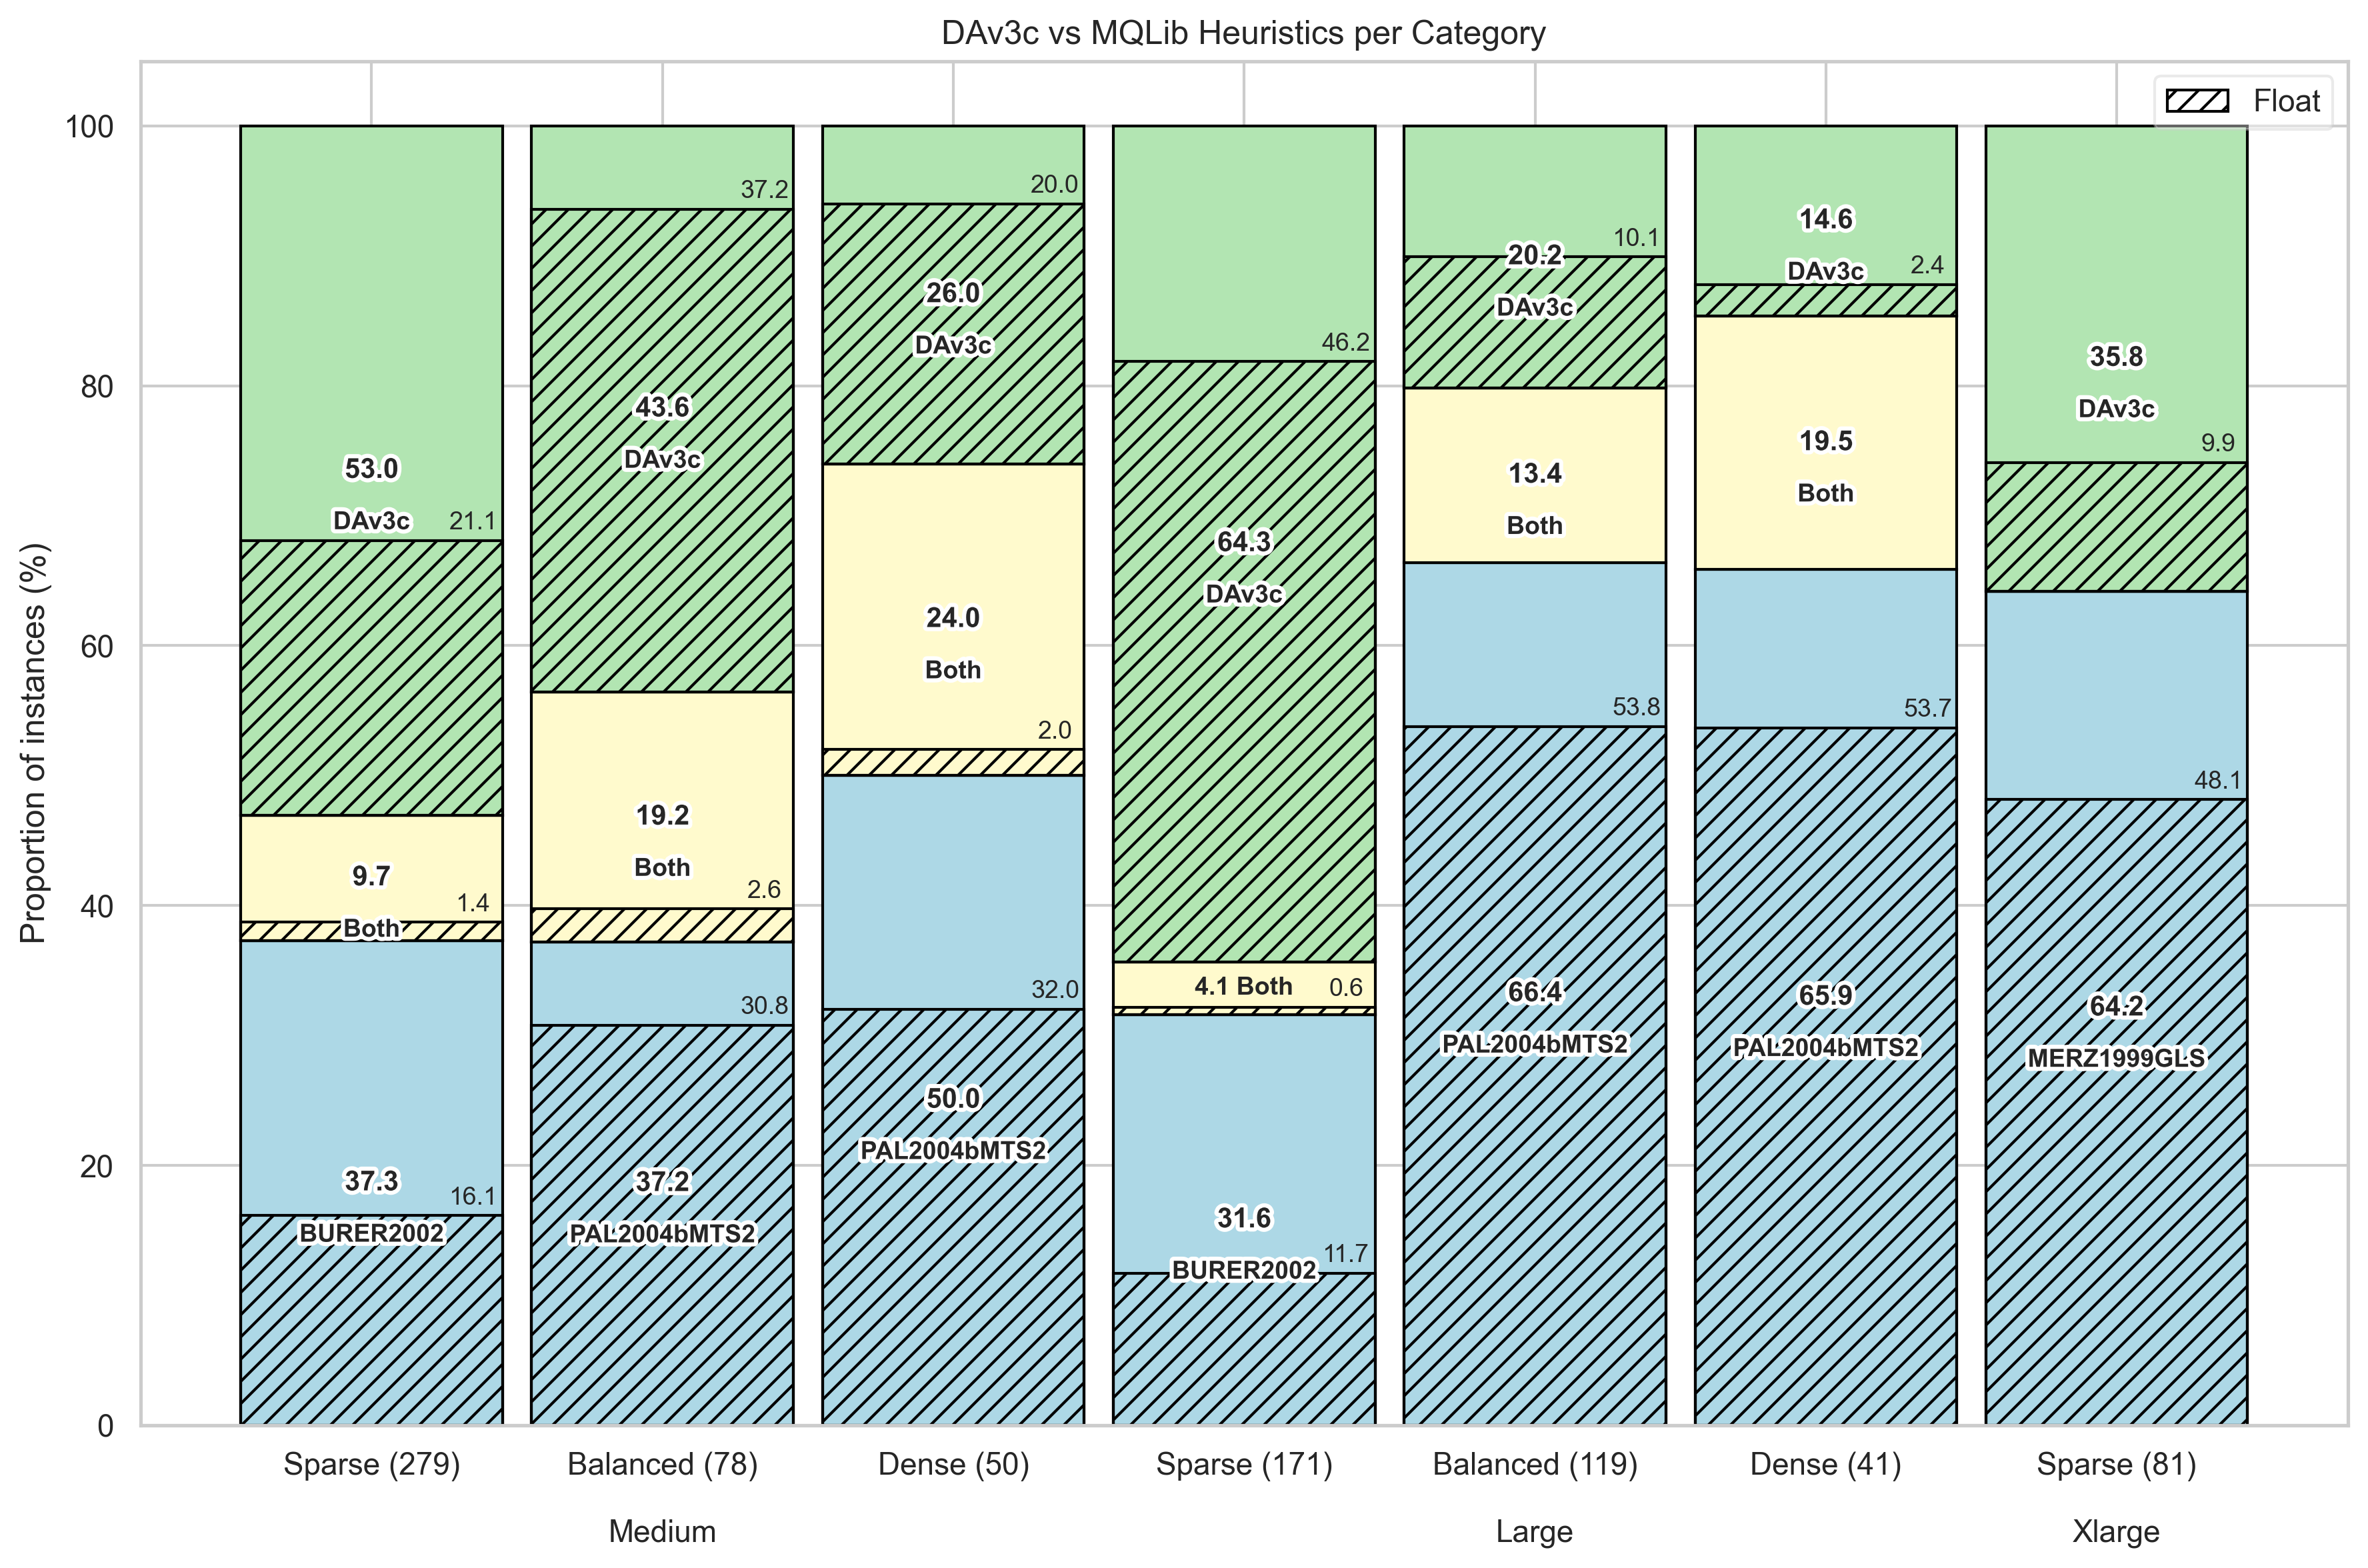

In [7]:
plotting.plot_win_tie_loss_with_float_hatch(
    summary=summary_heu,
    pivot_table=pivot_table_heu,
    title="DAv3c vs MQLib Heuristics per Category",
    win_label="DAv3c",
    loss_label="Heuristic",
    use_category_loss_labels=True,
    save_name="dav3c_vs_heuristics_category.pdf",
)

Validation check:
Tie count: 85
Ratio == 1.0: 85


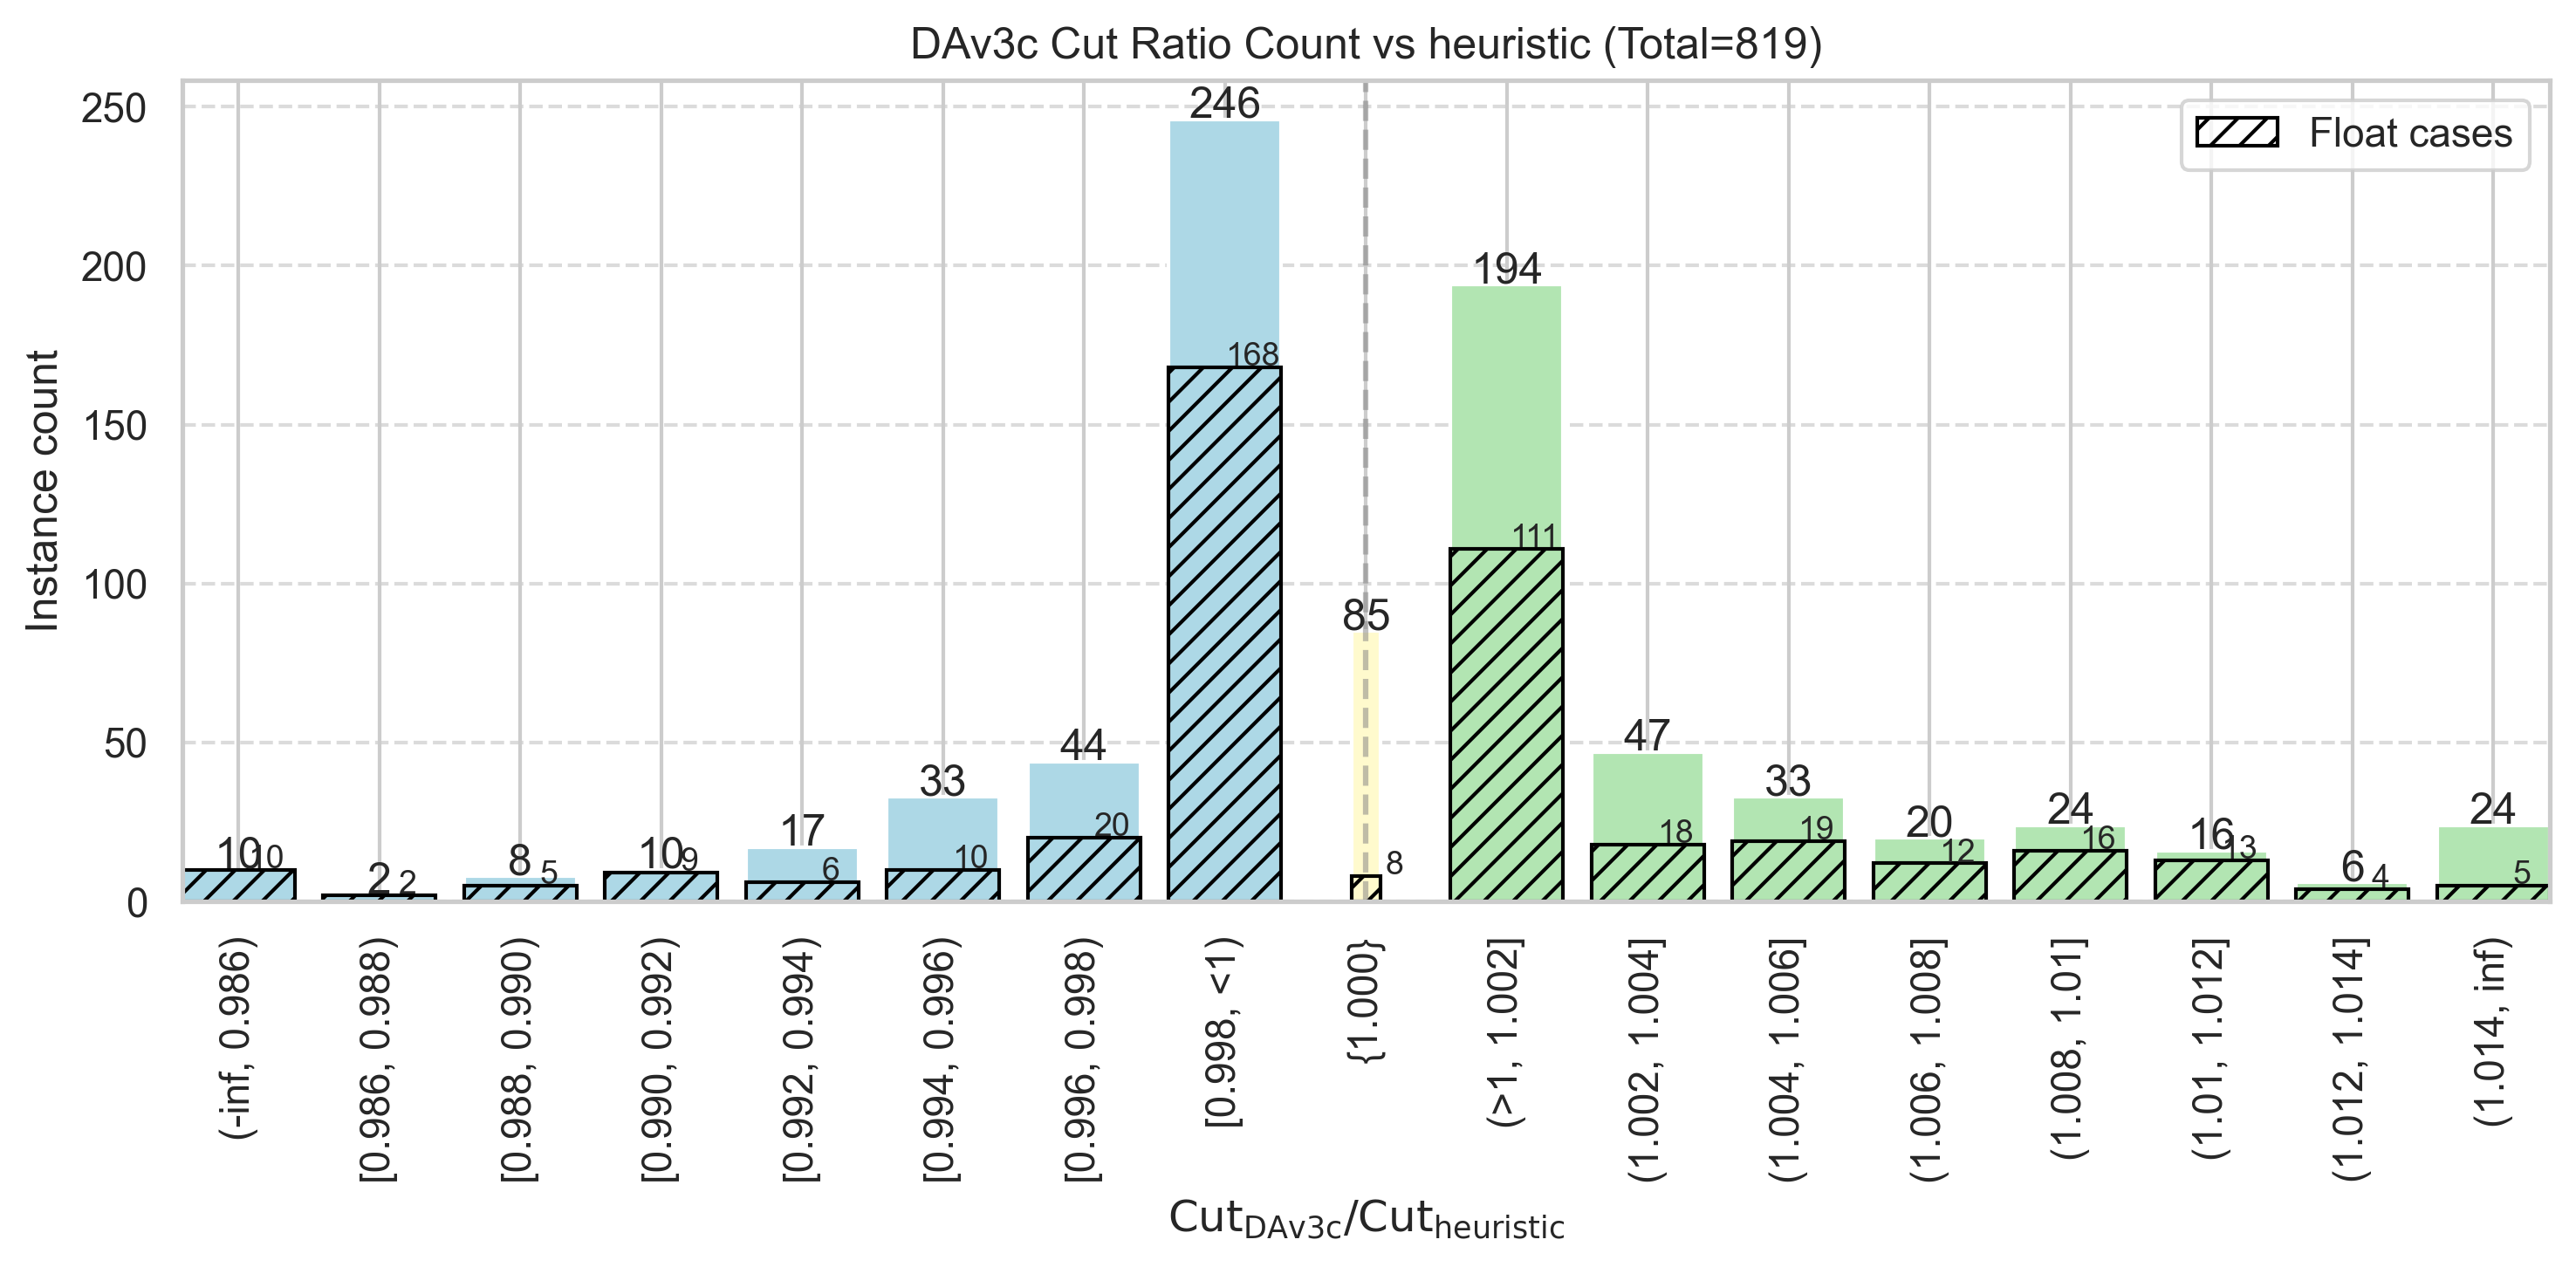

In [8]:
ratio_result_heu = utils.compute_cut_ratio_counts(
    df=df_heu,
    solver_col="DAv3c",
    baseline_col="heuristic",
    int_col="int_only",
)

print('Validation check:')
print("Tie count:", ratio_result_heu["tie_count"])
print("Ratio == 1.0:", ratio_result_heu["ratio_one_count"])

fig, ax = plotting.plot_cut_ratio_counts(
    ratio_result_heu,
    solver_label="DAv3c",
    baseline_label="heuristic",
    save_path=cfg.FIGURE_DIR / "DAv3c_Heuristics_Cut_Ratio_Count.pdf",
)

In [9]:
utils.run_wilcoxon(df_heu, "DAv3c", "heuristic", "DAv3c vs MQLib Heuristics")


=== DAv3c vs MQLib Heuristics ===
Total paired samples: 819
Numerical ties: 85
Samples used: 734
Wilcoxon statistic: 133771.5
p-value: 8.4806e-01
Rank-biserial correlation: -0.0082
Median difference: -4.23461e-09
Result: Not statistically significant (unadjusted)


{'n_total': 819,
 'n_nonzero': 734,
 'n_ties': 85,
 'stat': np.float64(133771.5),
 'p_raw': np.float64(0.8480572817359886),
 'r_rb': np.float64(-0.00816326530612245)}

In [10]:
eps_values = [0, 1e-9, 1e-8]

for eps in eps_values:
    results = utils.wilcoxon_by_category(
        df_heu,
        "DAv3c",
        "heuristic",
        eps=eps
    )

    print(f"\n=== Absolute tolerance: {eps} ===")

    display(
        results[
            [
                "category",
                "n_nonzero",
                "n_ties",
                "p_raw",
                "p_holm",
                "r_rb",
                "status"
            ]
        ]
    )


=== Absolute tolerance: 0 ===


,category,n_nonzero,n_ties,p_raw,p_holm,r_rb,status
0,large_balanced,103,16,4.449840e-05,2.224920e-04,-0.463406,Significant
1,large_dense,33,8,1.099177e-04,4.396709e-04,-0.729055,Significant
2,large_sparse,165,6,1.752789e-09,1.226952e-08,0.540270,Significant
3,medium_balanced,65,13,9.089513e-01,9.089513e-01,0.016317,Not significant
4,medium_dense,38,12,1.195506e-02,3.586517e-02,-0.462888,Significant
5,medium_sparse,256,23,1.207436e-02,3.586517e-02,0.180964,Significant
6,xlarge_sparse,81,0,1.957937e-06,1.174762e-05,-0.608552,Significant



=== Absolute tolerance: 1e-09 ===


,category,n_nonzero,n_ties,p_raw,p_holm,r_rb,status
0,large_balanced,103,16,4.449840e-05,2.224920e-04,-0.463406,Significant
1,large_dense,33,8,1.099177e-04,4.396709e-04,-0.729055,Significant
2,large_sparse,164,7,1.666406e-09,1.166484e-08,0.542646,Significant
3,medium_balanced,63,15,9.399703e-01,9.399703e-01,0.010913,Not significant
4,medium_dense,38,12,1.195506e-02,3.586517e-02,-0.462888,Significant
5,medium_sparse,252,27,1.279055e-02,3.586517e-02,0.180908,Significant
6,xlarge_sparse,81,0,1.957937e-06,1.174762e-05,-0.608552,Significant



=== Absolute tolerance: 1e-08 ===


,category,n_nonzero,n_ties,p_raw,p_holm,r_rb,status
0,large_balanced,102,17,5.102457e-05,2.551228e-04,-0.462022,Significant
1,large_dense,33,8,1.099177e-04,4.396709e-04,-0.729055,Significant
2,large_sparse,163,8,1.576246e-09,1.103372e-08,0.545114,Significant
3,medium_balanced,60,18,9.882530e-01,9.882530e-01,0.002186,Not significant
4,medium_dense,37,13,1.158695e-02,3.476084e-02,-0.470839,Significant
5,medium_sparse,252,27,1.279055e-02,3.476084e-02,0.180908,Significant
6,xlarge_sparse,81,0,1.957937e-06,1.174762e-05,-0.608552,Significant


In [11]:
res_heu = utils.wilcoxon_by_category(df_heu, "DAv3c", "heuristic")
utils.print_wilcoxon_Pairwise_results(res_heu , "DAv3c vs MQLib Heuristic (Category-wise)")


=== DAv3c vs MQLib Heuristic (Category-wise) ===
large_balanced       | n=103 | ties= 16 | p_raw=4.4498e-05 | p_holm=2.2249e-04 | r_rb=-0.463 | Significant
large_dense          | n= 33 | ties=  8 | p_raw=1.0992e-04 | p_holm=4.3967e-04 | r_rb=-0.729 | Significant
large_sparse         | n=164 | ties=  7 | p_raw=1.6664e-09 | p_holm=1.1665e-08 | r_rb=+0.543 | Significant
medium_balanced      | n= 63 | ties= 15 | p_raw=9.3997e-01 | p_holm=9.3997e-01 | r_rb=+0.011 | Not significant
medium_dense         | n= 38 | ties= 12 | p_raw=1.1955e-02 | p_holm=3.5865e-02 | r_rb=-0.463 | Significant
medium_sparse        | n=252 | ties= 27 | p_raw=1.2791e-02 | p_holm=3.5865e-02 | r_rb=+0.181 | Significant
xlarge_sparse        | n= 81 | ties=  0 | p_raw=1.9579e-06 | p_holm=1.1748e-05 | r_rb=-0.609 | Significant


In [12]:
import inspect

print(inspect.getsource(utils.print_wilcoxon_Pairwise_results))

def print_wilcoxon_Pairwise_results(results, title):
    print(f"\n=== {title} ===")

    for _, row in results.iterrows():
        cat = str(row["category"])
        n = int(row["n_nonzero"])
        ties = int(row["n_ties"])

        if pd.isna(row["p_raw"]):
            print(
                f"{cat:20s} | "
                f"n={n:3d} | ties={ties:3d} | "
                f"Skipped ({row['status']})"
            )
        else:
            print(
                f"{cat:20s} | "
                f"n={n:3d} | ties={ties:3d} | "
                f"p_raw={row['p_raw']:.4e} | "
                f"p_holm={row['p_holm']:.4e} | "
                f"r_rb={row['r_rb']:+.3f} | "
                f"{row['status']}"
            )



In [13]:
df_dav3 = utils.filter_main_instances(df_baseline,'DAv3')
df_dav3["category"] = (df_dav3["size_cat"] + "_" + df_dav3["density_cat"])
print(f'Total Number of Instances: {len(df_dav3)}')
print('............')
print(f'Size Category Distribution: {df_dav3['size_cat'].value_counts()}')
print('............')
print(f'Density Category Distribution: {df_dav3['density_cat'].value_counts()}')
print('............')
print(f'Density Category Distribution: {df_dav3['category'].value_counts()}')

Total Number of Instances: 819
............
Size Category Distribution: size_cat
medium    407
large     331
xlarge     81
Name: count, dtype: int64
............
Density Category Distribution: density_cat
sparse      531
balanced    197
dense        91
Name: count, dtype: int64
............
Density Category Distribution: category
medium_sparse      279
large_sparse       171
large_balanced     119
xlarge_sparse       81
medium_balanced     78
medium_dense        50
large_dense         41
Name: count, dtype: int64


In [14]:
df_dav3['result'] = df_dav3.apply(lambda row: utils.compare_scores(row["DAv2"], row["DAv3"]), axis=1)
pivot_table_dav3, summary_dav3 = utils.conparison_summary(df_dav3)
print(pivot_table_dav3)

result         category int_only   loss   tie   win weight_type  total
0         medium_sparse    False   41.0  15.0  52.0       float  108.0
1         medium_sparse     True   61.0  68.0  42.0     integer  171.0
14        medium_sparse    total  102.0  83.0  94.0       total  279.0
2       medium_balanced    False   19.0  15.0  21.0       float   55.0
3       medium_balanced     True   10.0  13.0   0.0     integer   23.0
15      medium_balanced    total   29.0  28.0  21.0       total   78.0
4          medium_dense    False    6.0   4.0  17.0       float   27.0
5          medium_dense     True    6.0  16.0   1.0     integer   23.0
16         medium_dense    total   12.0  20.0  18.0       total   50.0
6          large_sparse    False   60.0   2.0  38.0       float  100.0
7          large_sparse     True   45.0  22.0   4.0     integer   71.0
17         large_sparse    total  105.0  24.0  42.0       total  171.0
8        large_balanced    False   30.0   5.0  41.0       float   76.0
9     

(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv2 vs DAv3 per Category'}, ylabel='Proportion of instances (%)'>)

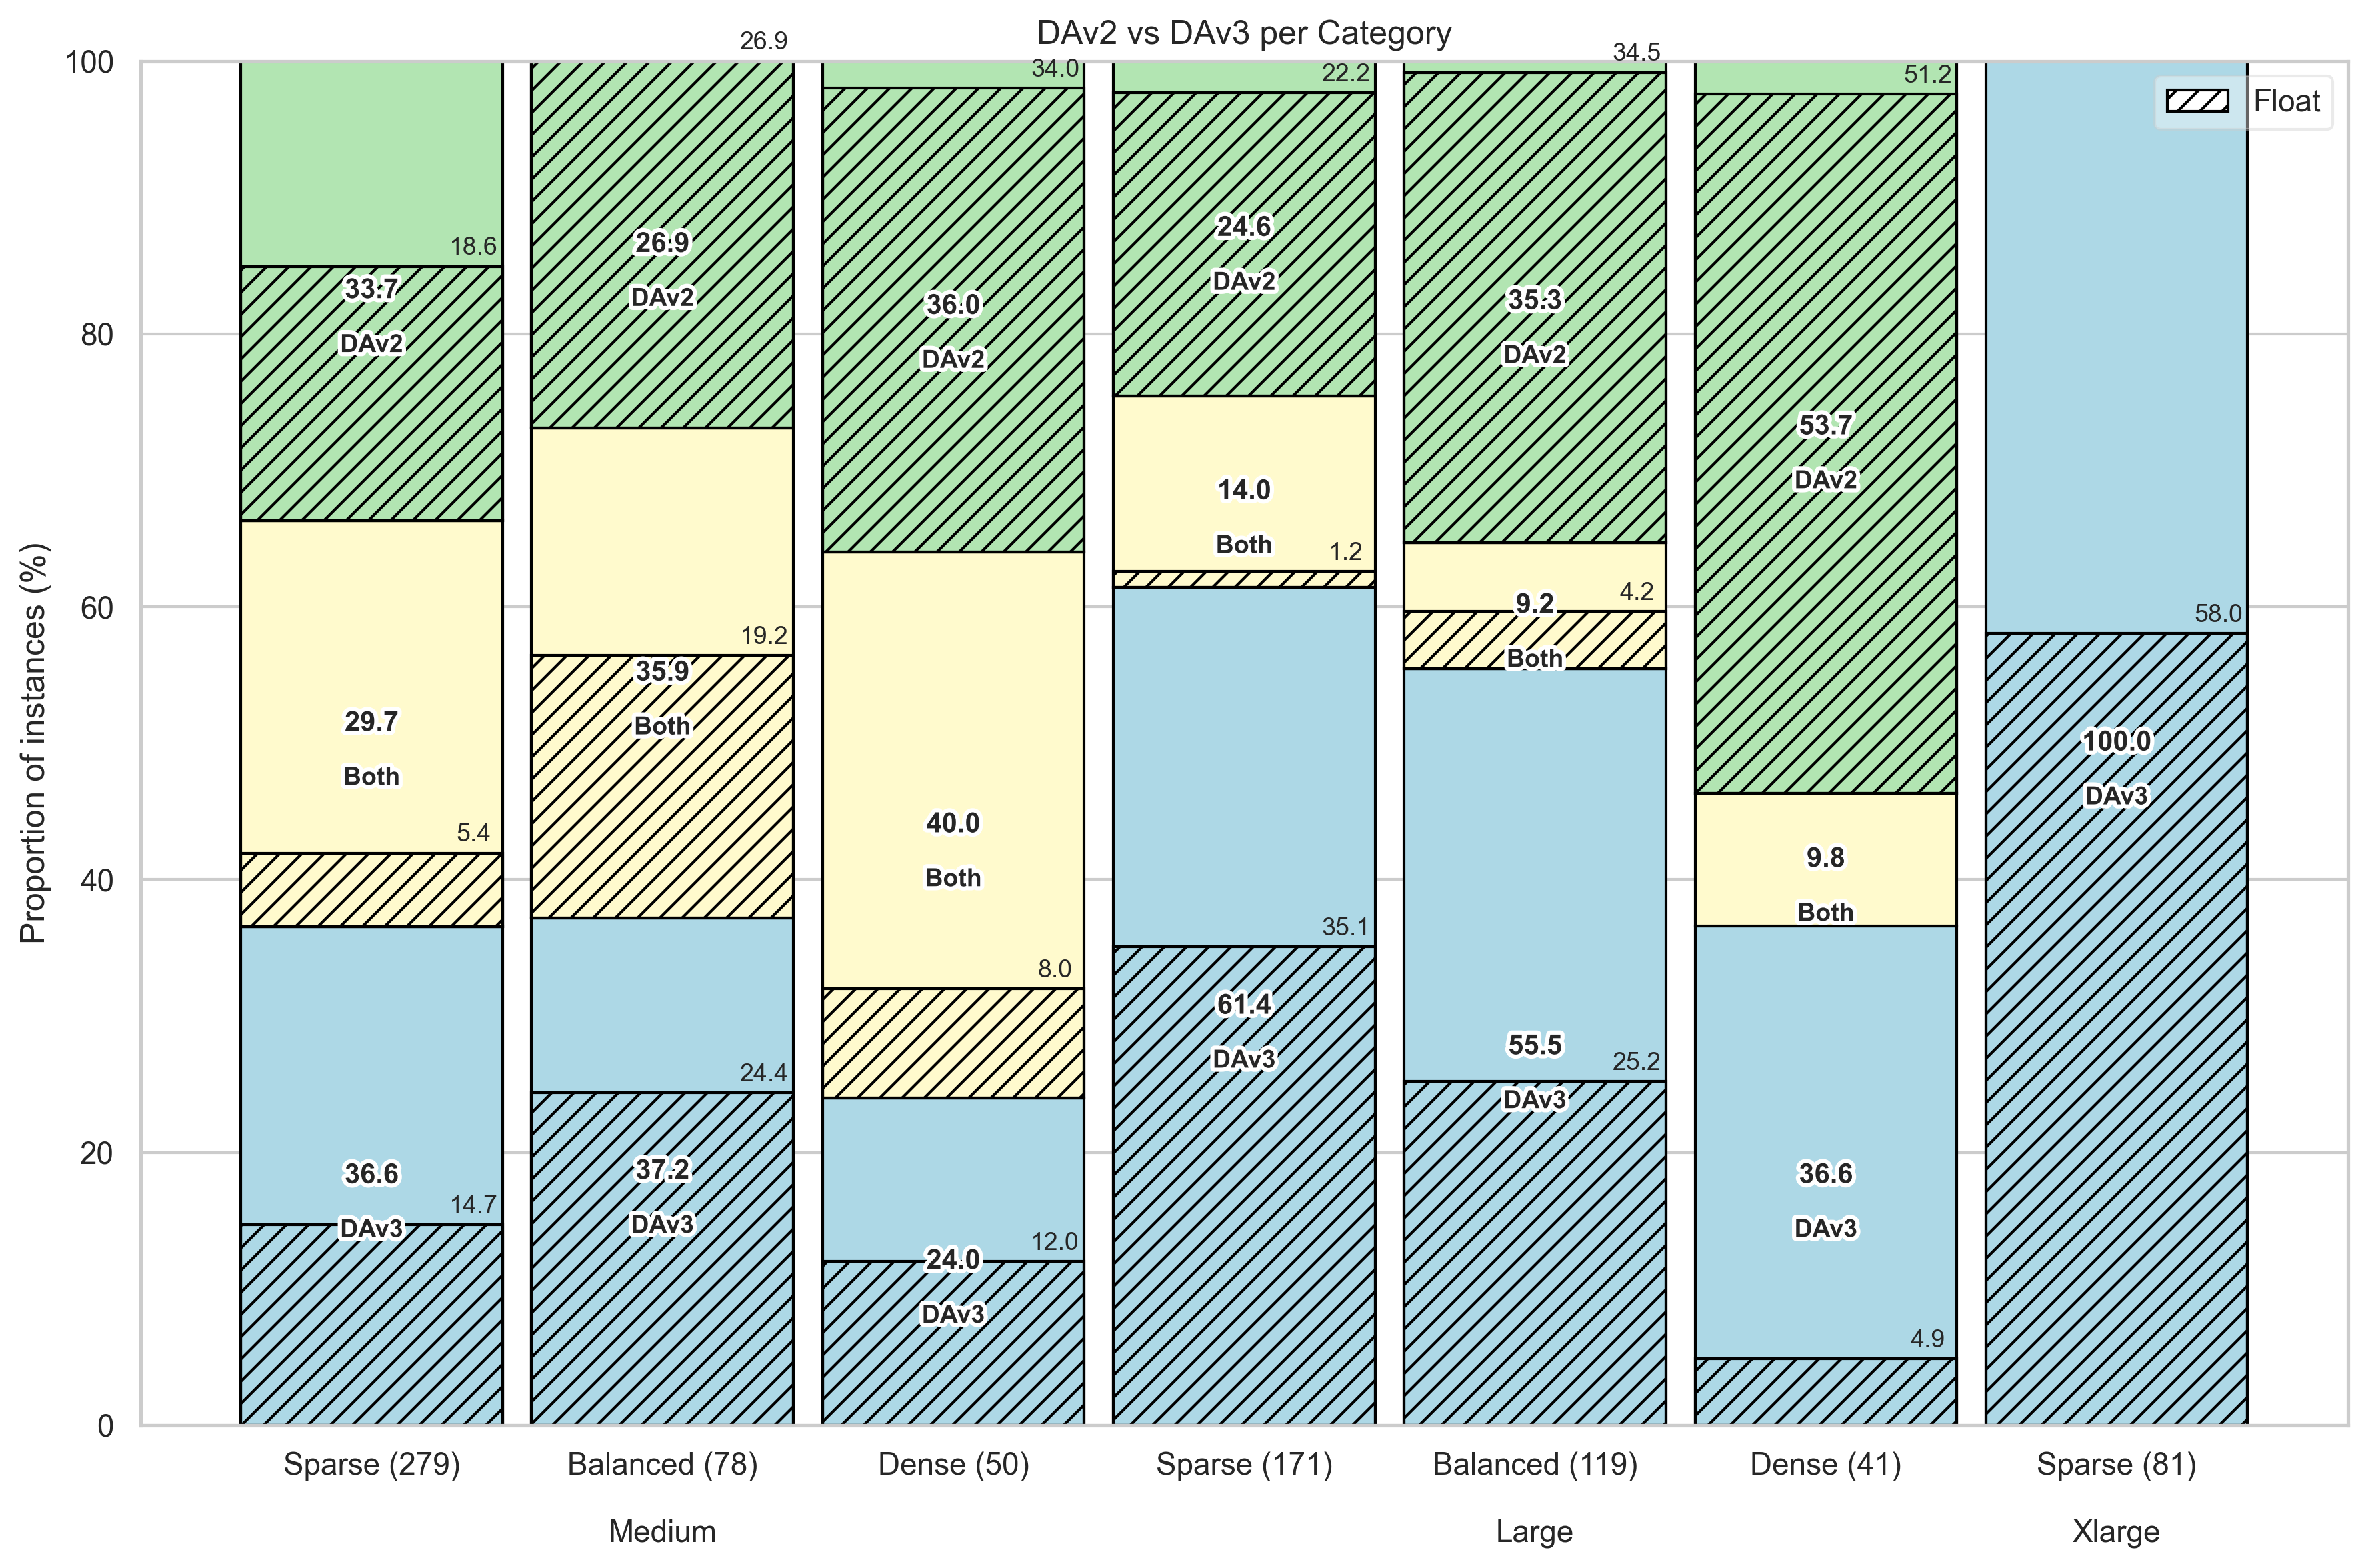

In [15]:
plotting.plot_win_tie_loss_with_float_hatch(
    summary=summary_dav3,
    pivot_table=pivot_table_dav3,
    title="DAv2 vs DAv3 per Category",
    win_label="DAv2",
    loss_label="DAv3",
    use_category_loss_labels=False,
    save_name="dav2_vs_dav3_category.pdf",
)

Validation check:
Tie count: 170
Ratio == 1.0: 170


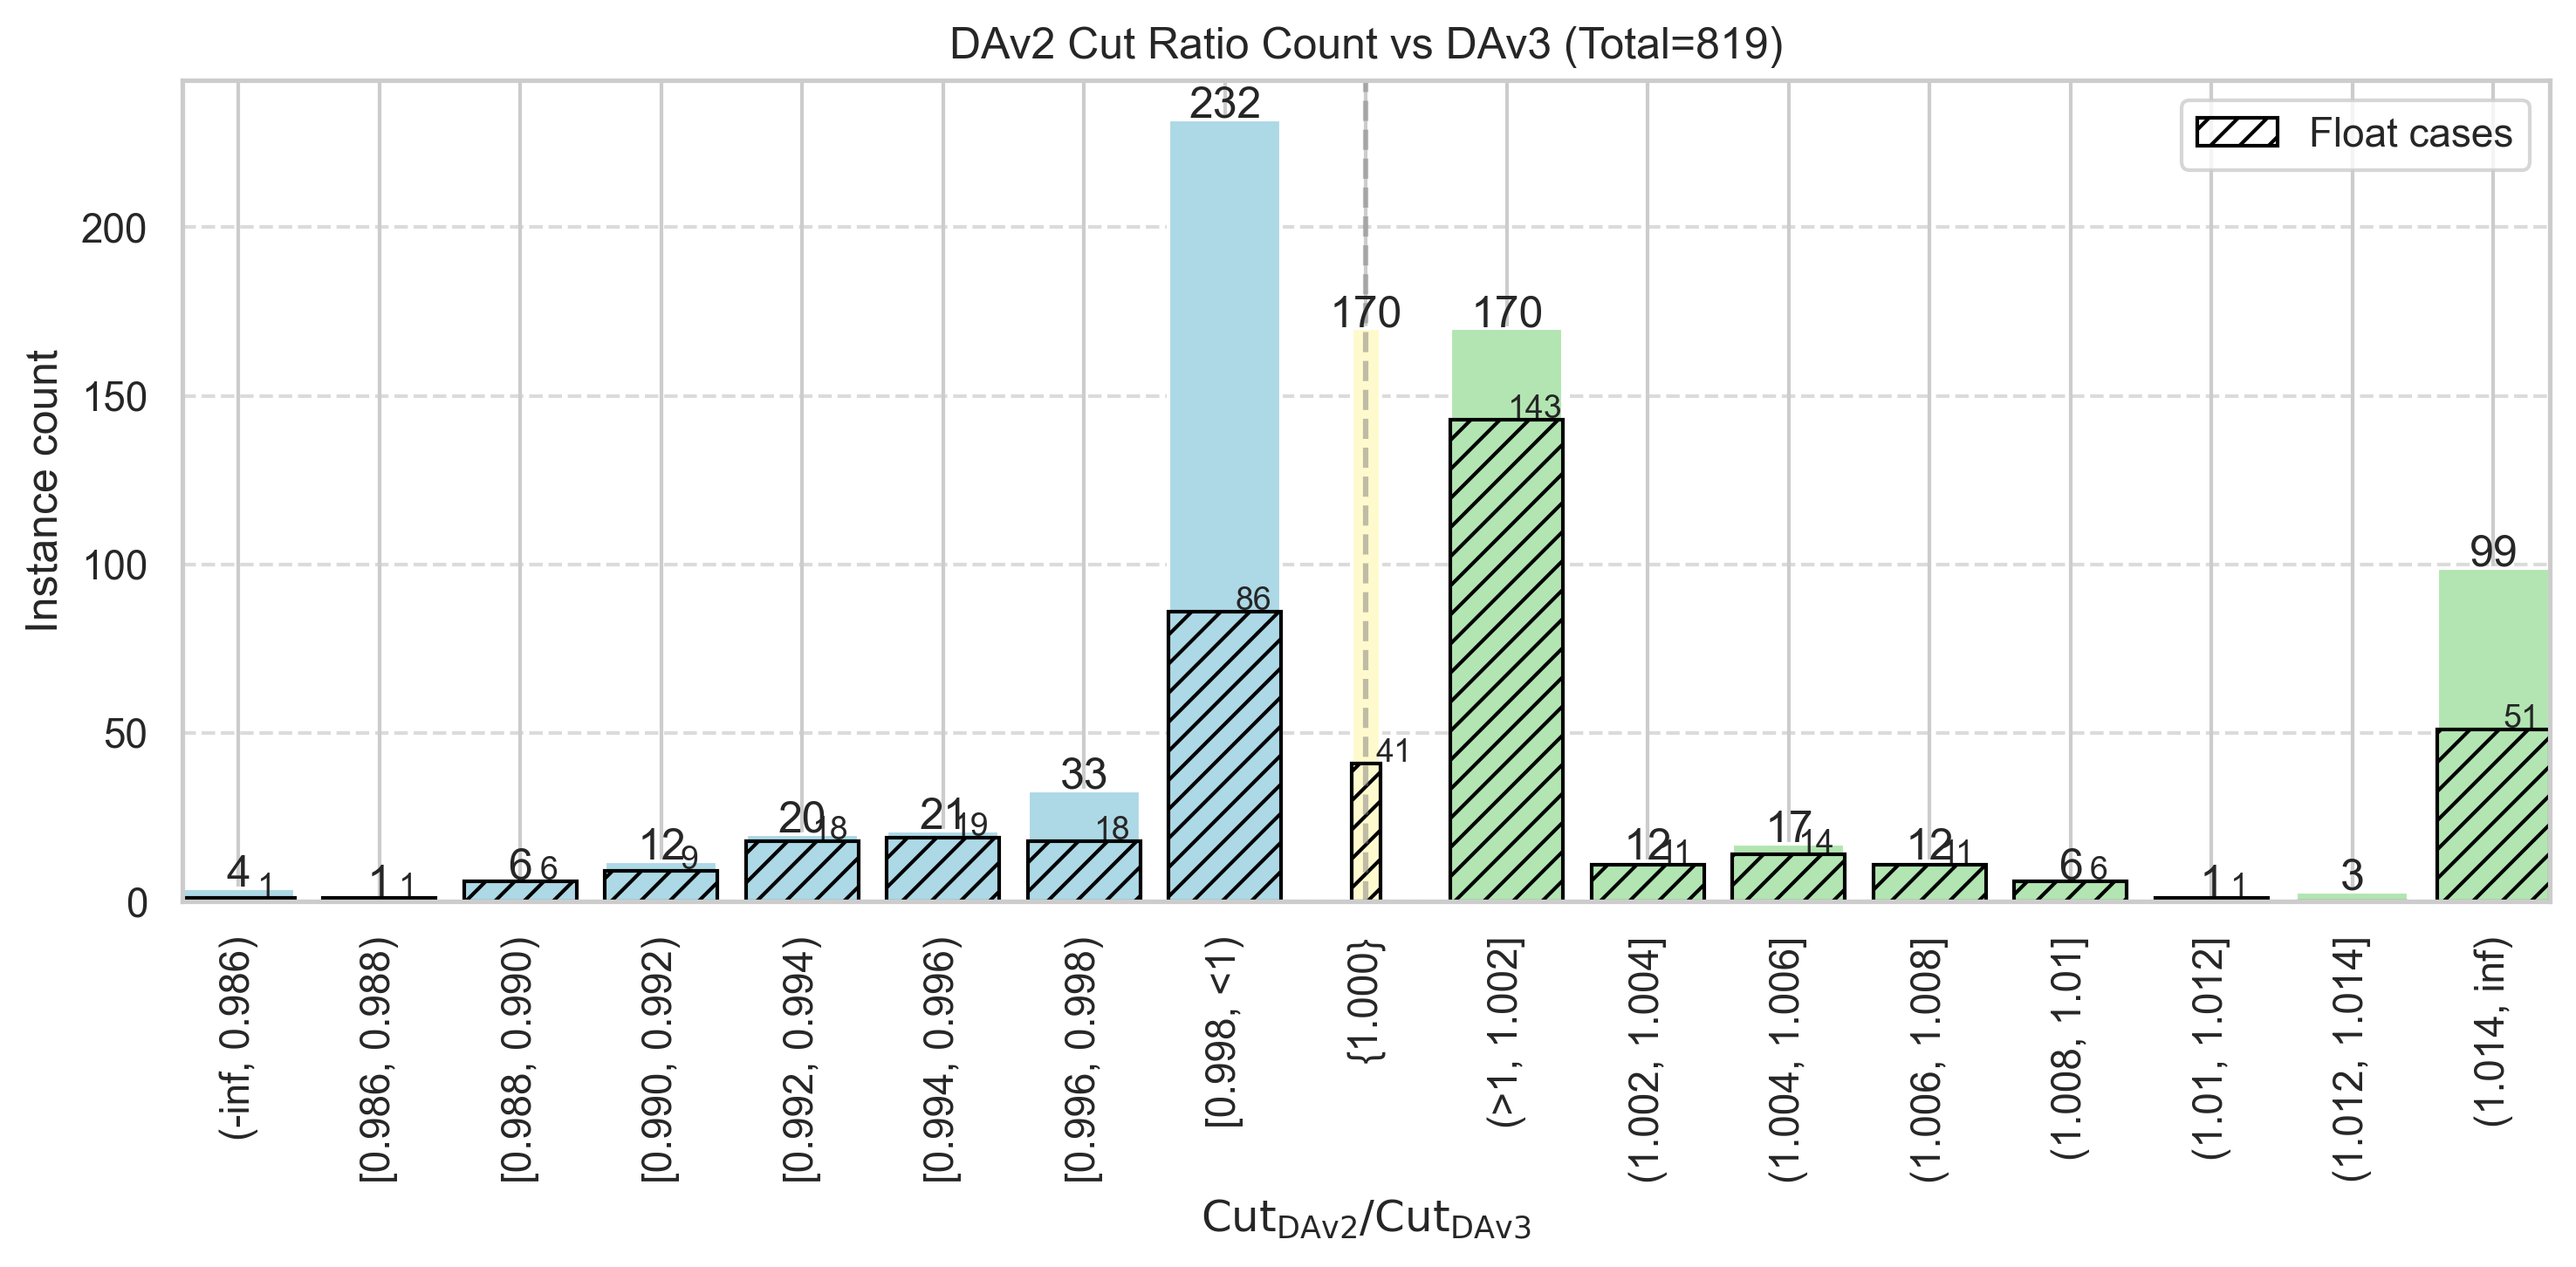

In [16]:
ratio_result_dav3 = utils.compute_cut_ratio_counts(
    df=df_dav3,
    solver_col="DAv2",
    baseline_col="DAv3",
    int_col="int_only",
)

print('Validation check:')
print("Tie count:", ratio_result_dav3["tie_count"])
print("Ratio == 1.0:", ratio_result_dav3["ratio_one_count"])

fig, ax = plotting.plot_cut_ratio_counts(
    ratio_result_dav3,
    solver_label="DAv2",
    baseline_label="DAv3",
    save_path=cfg.FIGURE_DIR / "DAv2_DAv3_Cut_Ratio_Count.svg",
)

In [17]:
utils.run_wilcoxon(df_dav3, "DAv2", "DAv3", "DAv2 vs DAv3")


=== DAv2 vs DAv3 ===
Total paired samples: 738
Numerical ties: 170
Samples used: 568
Wilcoxon statistic: 66422.5
p-value: 2.3894e-04
Rank-biserial correlation: -0.1779
Median difference: -6
Result: Statistically significant (unadjusted)


{'n_total': 738,
 'n_nonzero': 568,
 'n_ties': 170,
 'stat': np.float64(66422.5),
 'p_raw': np.float64(0.00023894206761469256),
 'r_rb': np.float64(-0.17791900789623505)}

In [18]:
res_dav3 = utils.wilcoxon_by_category(df_dav3, "DAv2", "DAv3")
utils.print_wilcoxon_Pairwise_results(res_dav3 , "DAv2 vs DAv3 (Category-wise)")


=== DAv2 vs DAv3 (Category-wise) ===
large_balanced       | n=108 | ties= 11 | p_raw=2.2366e-01 | p_holm=1.0000e+00 | r_rb=-0.135 | Not significant
large_dense          | n= 37 | ties=  4 | p_raw=5.3068e-01 | p_holm=1.0000e+00 | r_rb=+0.121 | Not significant
large_sparse         | n=147 | ties= 24 | p_raw=5.8266e-07 | p_holm=3.4960e-06 | r_rb=-0.475 | Significant
medium_balanced      | n= 50 | ties= 28 | p_raw=5.1466e-01 | p_holm=1.0000e+00 | r_rb=-0.106 | Not significant
medium_dense         | n= 30 | ties= 20 | p_raw=3.9305e-01 | p_holm=1.0000e+00 | r_rb=+0.183 | Not significant
medium_sparse        | n=196 | ties= 83 | p_raw=6.4125e-01 | p_holm=1.0000e+00 | r_rb=-0.038 | Not significant
xlarge_sparse        | n=  0 | ties=  0 | Skipped (Too small)


In [19]:
df_dav3['result'] = df_dav3.apply(lambda row: utils.compare_scores(row["DAv3c"], row["DAv3"]), axis=1)
pivot_table_dav3, summary_dav3 = utils.conparison_summary(df_dav3)
print(pivot_table_dav3)

result         category int_only   loss   tie   win weight_type  total
0         medium_sparse    False   84.0   5.0  19.0       float  108.0
1         medium_sparse     True  103.0  43.0  25.0     integer  171.0
14        medium_sparse    total  187.0  48.0  44.0       total  279.0
2       medium_balanced    False   33.0   3.0  19.0       float   55.0
3       medium_balanced     True    9.0  14.0   0.0     integer   23.0
15      medium_balanced    total   42.0  17.0  19.0       total   78.0
4          medium_dense    False   21.0   1.0   5.0       float   27.0
5          medium_dense     True   12.0  11.0   0.0     integer   23.0
16         medium_dense    total   33.0  12.0   5.0       total   50.0
6          large_sparse    False   49.0   1.0  50.0       float  100.0
7          large_sparse     True   59.0  11.0   1.0     integer   71.0
17         large_sparse    total  108.0  12.0  51.0       total  171.0
8        large_balanced    False   63.0   0.0  13.0       float   76.0
9     

In [20]:
print(summary_dav3)

{'medium_sparse_flt': (84.0, 5.0, 19.0), 'medium_sparse': (187.0, 48.0, 44.0), 'medium_balanced_flt': (33.0, 3.0, 19.0), 'medium_balanced': (42.0, 17.0, 19.0), 'medium_dense_flt': (21.0, 1.0, 5.0), 'medium_dense': (33.0, 12.0, 5.0), 'large_sparse_flt': (49.0, 1.0, 50.0), 'large_sparse': (108.0, 12.0, 51.0), 'large_balanced_flt': (63.0, 0.0, 13.0), 'large_balanced': (83.0, 23.0, 13.0), 'large_dense_flt': (20.0, 0.0, 3.0), 'large_dense': (28.0, 10.0, 3.0), 'xlarge_sparse_flt': (15.0, 0.0, 32.0), 'xlarge_sparse': (20.0, 0.0, 61.0)}


(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv3c vs DAv3 per Category'}, ylabel='Proportion of instances (%)'>)

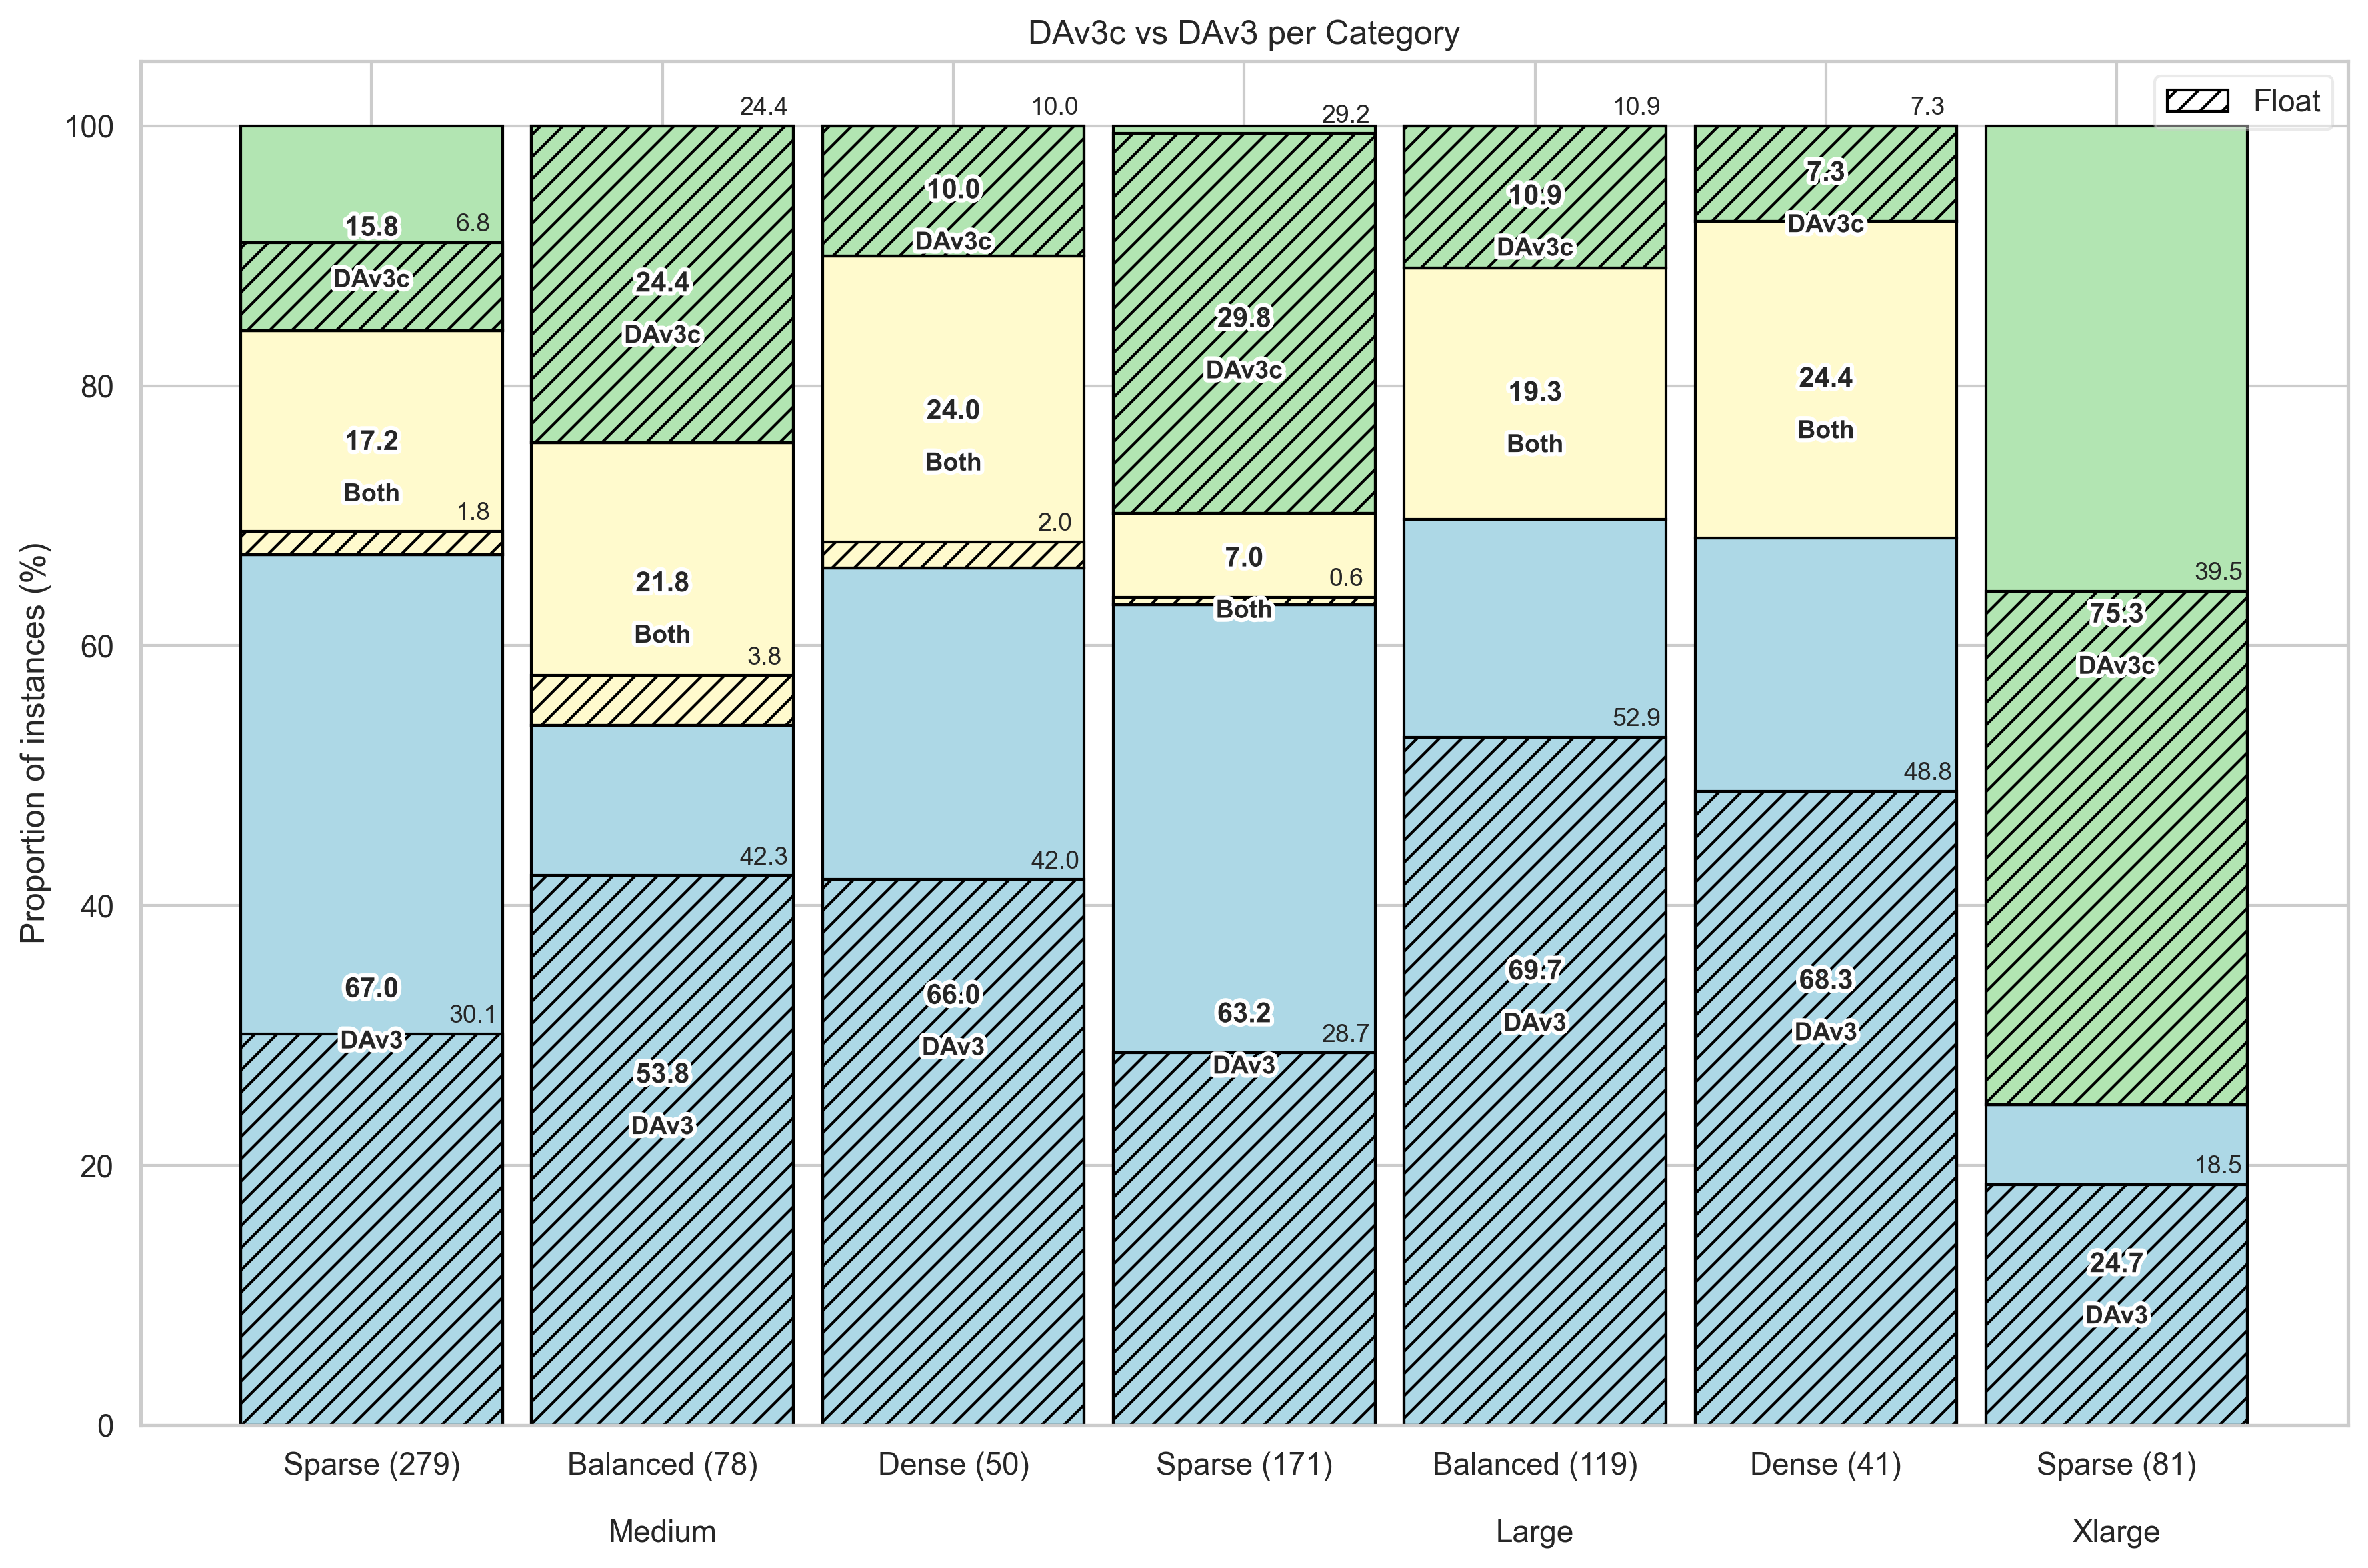

In [21]:
plotting.plot_win_tie_loss_with_float_hatch(
    summary=summary_dav3,
    pivot_table=pivot_table_dav3,
    title="DAv3c vs DAv3 per Category",
    win_label="DAv3c",
    loss_label="DAv3",
    use_category_loss_labels=False,
    save_name="dav3c_vs_dav3_category.pdf",
)

In [22]:
df_dav3_new = df_dav3[df_dav3['size_cat'] != 'xlarge'].copy()

Validation check:
Tie count: 122
Ratio == 1.0: 122


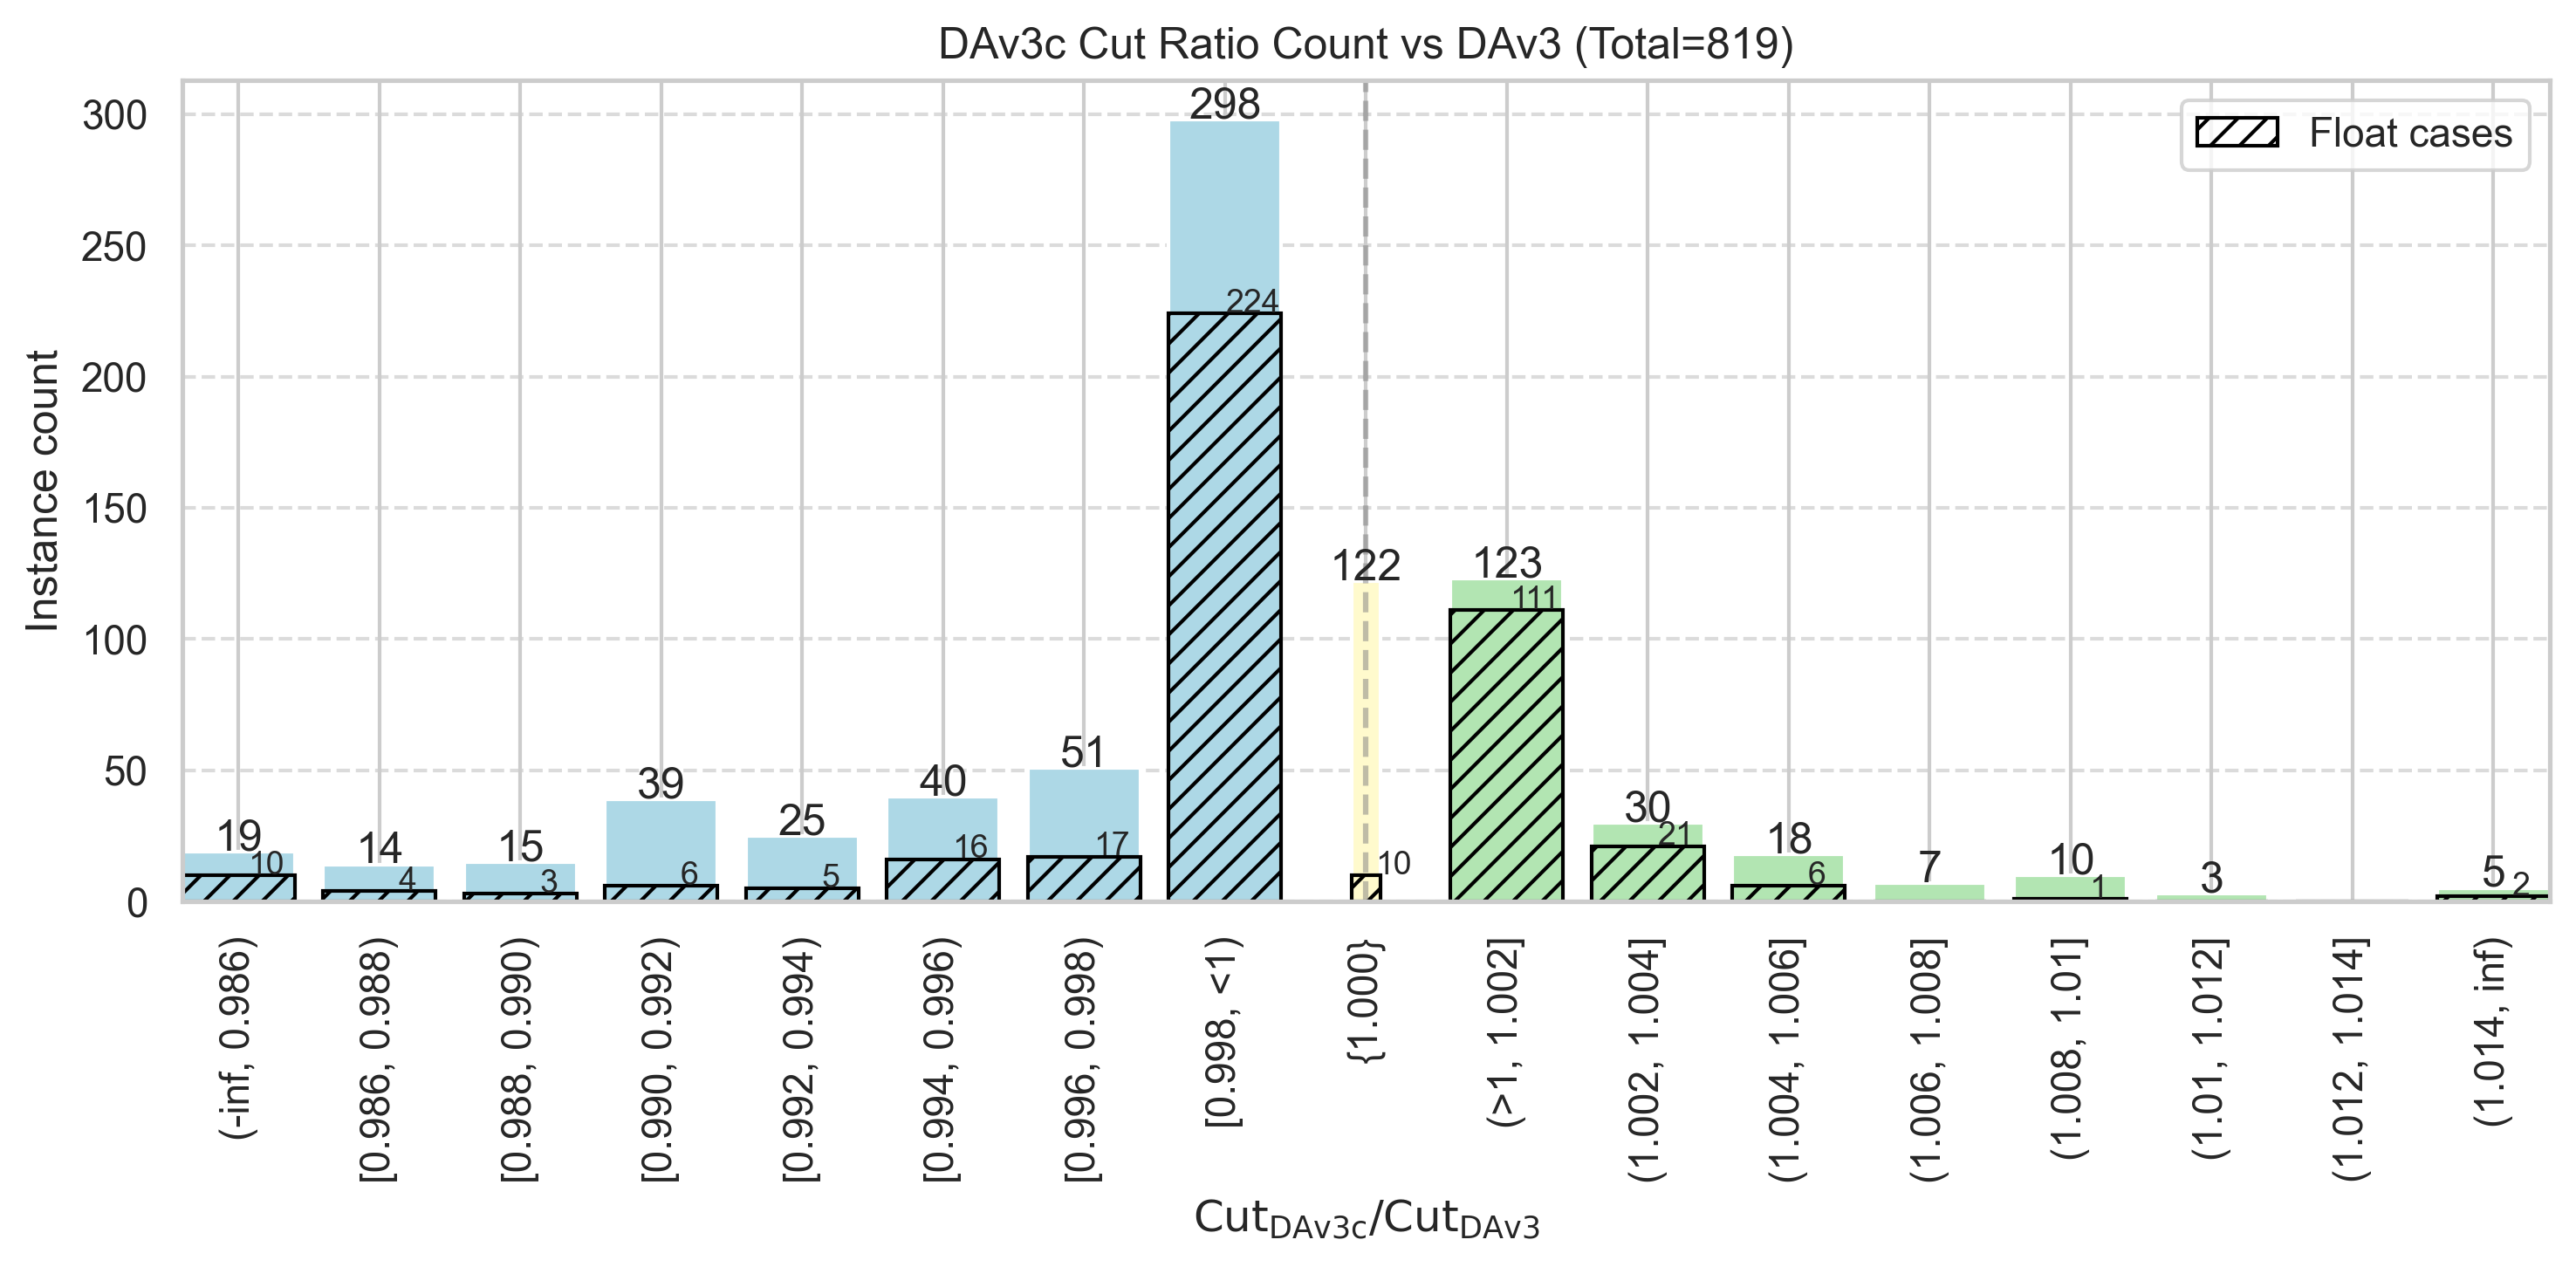

In [23]:
ratio_result_dav3_new = utils.compute_cut_ratio_counts(
    df=df_dav3 ,
    solver_col="DAv3c",
    baseline_col="DAv3",
    int_col="int_only",
)

print('Validation check:')
print("Tie count:", ratio_result_dav3_new["tie_count"])
print("Ratio == 1.0:", ratio_result_dav3_new["ratio_one_count"])

fig, ax = plotting.plot_cut_ratio_counts(
    ratio_result_dav3_new,
    solver_label="DAv3c",
    baseline_label="DAv3",
    save_path=cfg.FIGURE_DIR / "DAv3c_DAv3_Cut_Ratio_Count.pdf",
)

Validation check:
Tie count: 122
Ratio == 1.0: 122


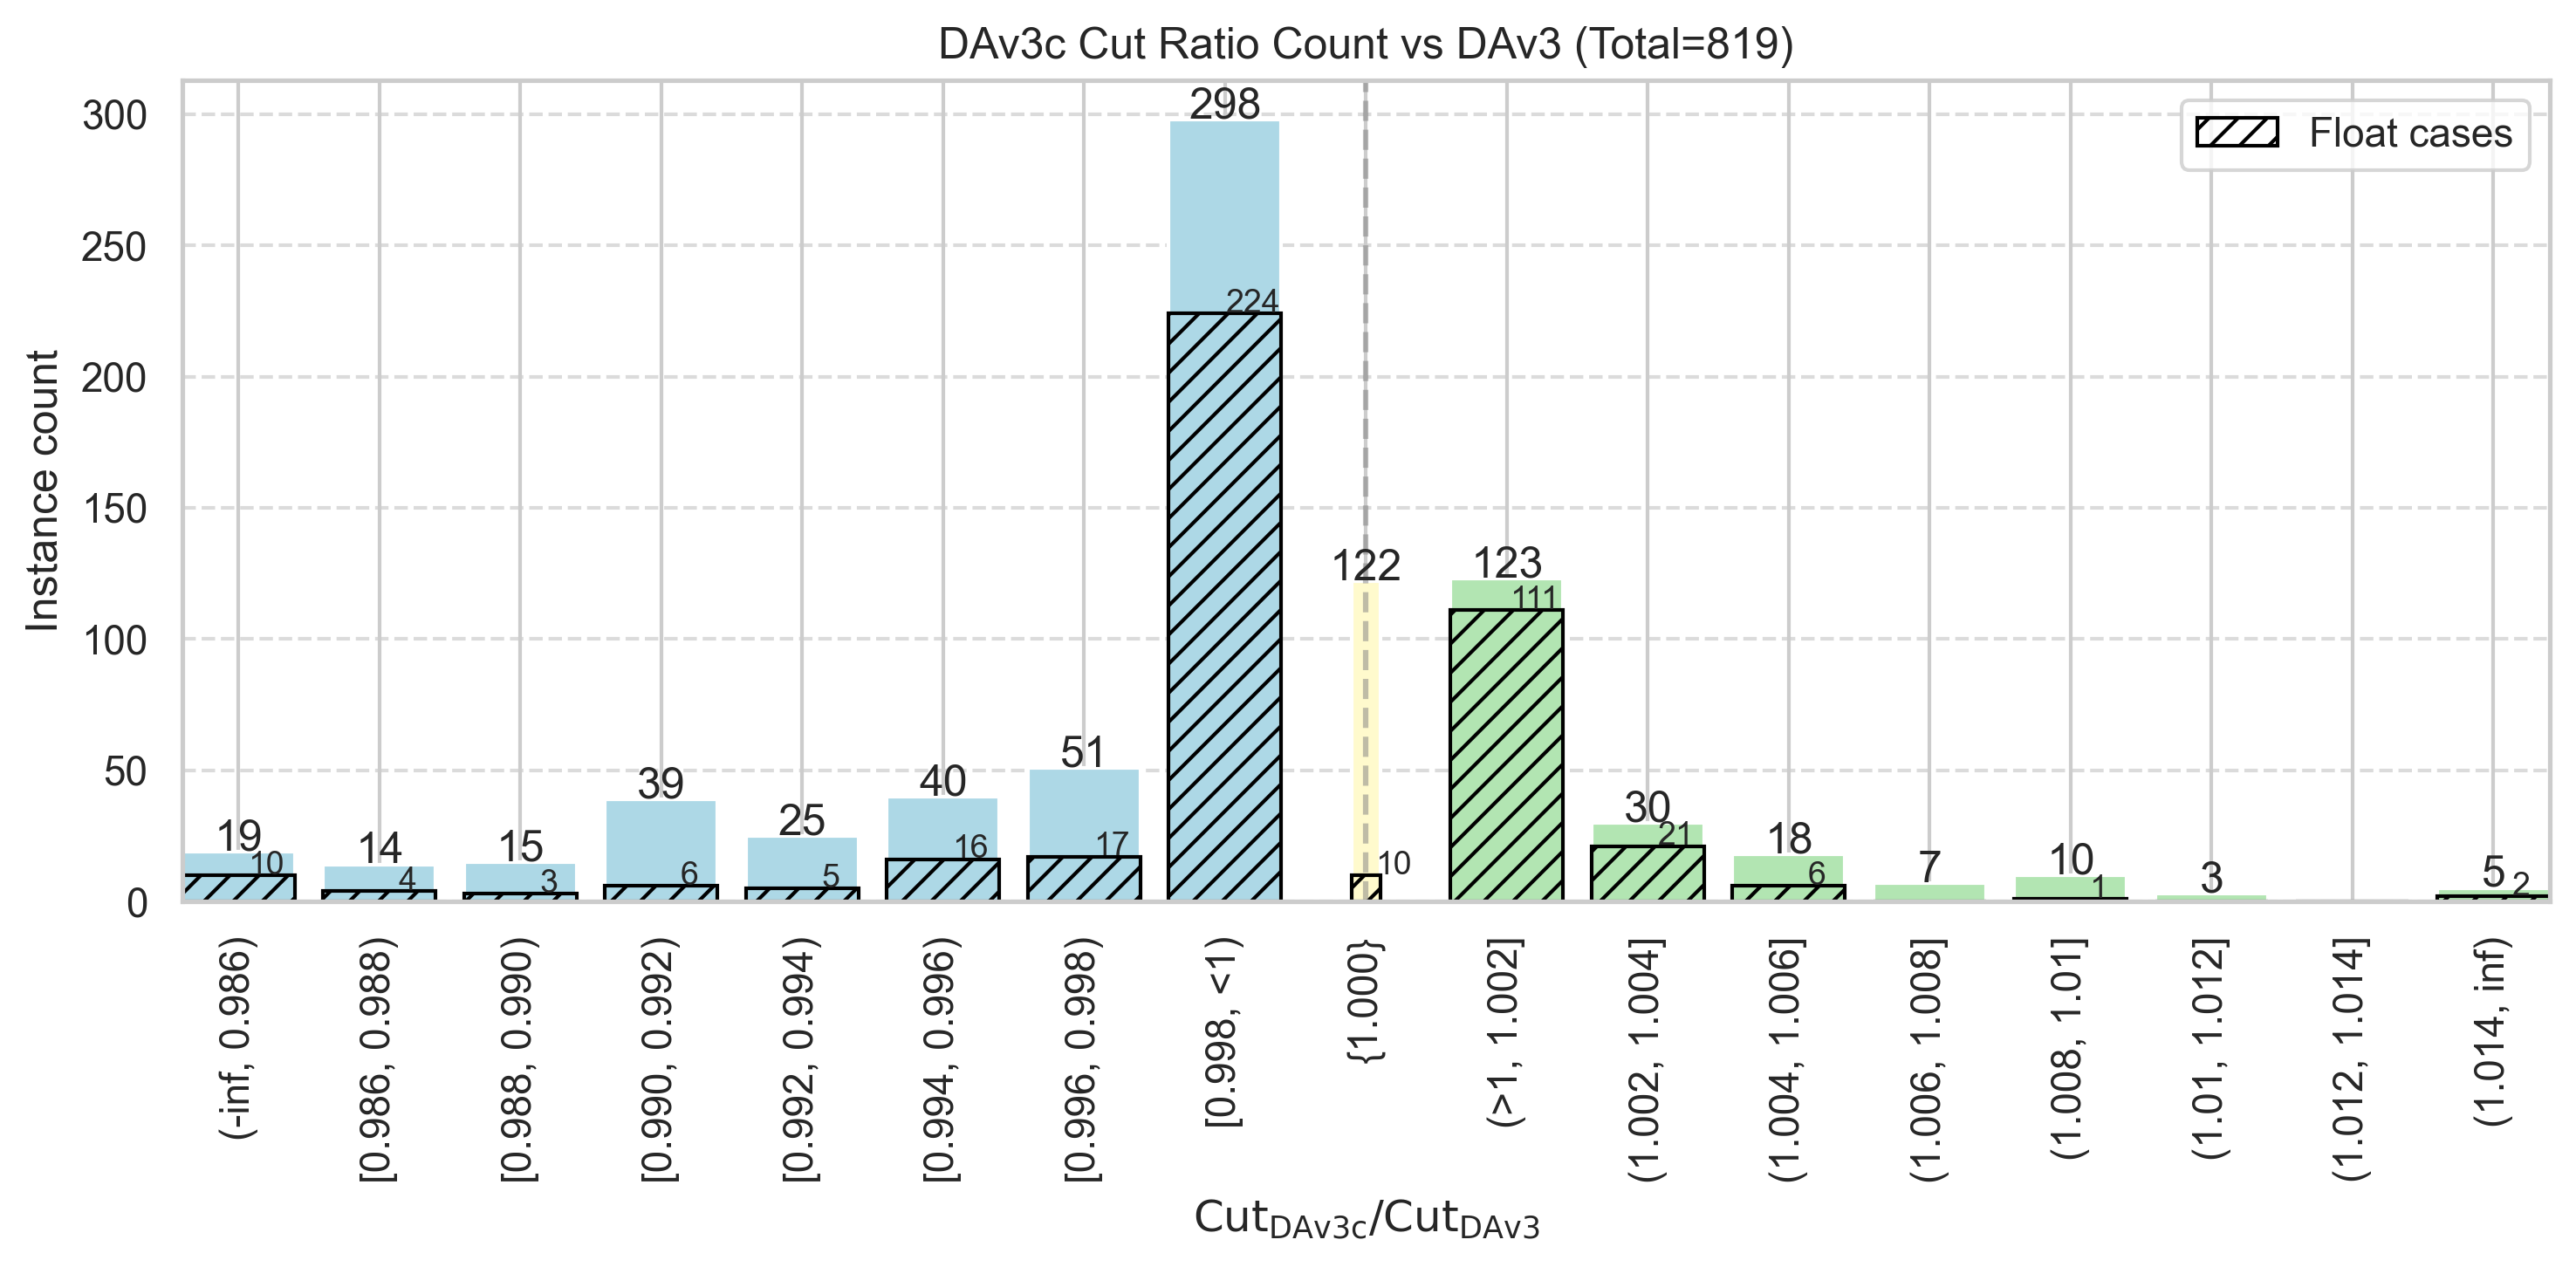

In [24]:
ratio_result_dav3 = utils.compute_cut_ratio_counts(
    df=df_dav3,
    solver_col="DAv3c",
    baseline_col="DAv3",
    int_col="int_only",
)

print('Validation check:')
print("Tie count:", ratio_result_dav3["tie_count"])
print("Ratio == 1.0:", ratio_result_dav3["ratio_one_count"])

fig, ax = plotting.plot_cut_ratio_counts(
    ratio_result_dav3,
    solver_label="DAv3c",
    baseline_label="DAv3",
    save_path=cfg.FIGURE_DIR / "DAv3c_DAv3_Cut_Ratio_Count.svg",
)

In [25]:
utils.run_wilcoxon(df_dav3, "DAv3c", "DAv3", "DAv3c vs DAv3")


=== DAv3c vs DAv3 ===
Total paired samples: 819
Numerical ties: 122
Samples used: 697
Wilcoxon statistic: 78120.0
p-value: 2.8052e-16
Rank-biserial correlation: -0.3577
Median difference: -83.7511
Result: Statistically significant (unadjusted)


{'n_total': 819,
 'n_nonzero': 697,
 'n_ties': 122,
 'stat': np.float64(78120.0),
 'p_raw': np.float64(2.8052213788537224e-16),
 'r_rb': np.float64(-0.3577057631355009)}

In [26]:
res_dav3 = utils.wilcoxon_by_category(df_dav3, "DAv3c", "DAv3")
utils.print_wilcoxon_Pairwise_results(res_dav3 , "DAv3c vs DAv3 (Category-wise)")


=== DAv3c vs DAv3 (Category-wise) ===
large_balanced       | n= 96 | ties= 23 | p_raw=5.0163e-11 | p_holm=3.5114e-10 | r_rb=-0.772 | Significant
large_dense          | n= 31 | ties= 10 | p_raw=2.2119e-06 | p_holm=8.8476e-06 | r_rb=-0.875 | Significant
large_sparse         | n=159 | ties= 12 | p_raw=5.7383e-04 | p_holm=5.7383e-04 | r_rb=-0.315 | Significant
medium_balanced      | n= 61 | ties= 17 | p_raw=8.6590e-05 | p_holm=1.7318e-04 | r_rb=-0.578 | Significant
medium_dense         | n= 38 | ties= 12 | p_raw=4.6266e-07 | p_holm=2.3133e-06 | r_rb=-0.849 | Significant
medium_sparse        | n=231 | ties= 48 | p_raw=8.5845e-11 | p_holm=5.1507e-10 | r_rb=-0.493 | Significant
xlarge_sparse        | n= 81 | ties=  0 | p_raw=4.9881e-05 | p_holm=1.4964e-04 | r_rb=+0.519 | Significant


In [27]:
df_dav2 = utils.filter_main_instances(df_baseline,'DAv2')
df_dav2["category"] = (df_dav2["size_cat"] + "_" + df_dav2["density_cat"])
print(f'Total Number of Instances: {len(df_dav2)}')
print('............')
print(f'Size Category Distribution: {df_dav2['size_cat'].value_counts()}')
print('............')
print(f'Density Category Distribution: {df_dav2['density_cat'].value_counts()}')
print('............')
print(f'Density Category Distribution: {df_dav2['category'].value_counts()}')

Total Number of Instances: 738
............
Size Category Distribution: size_cat
medium    407
large     331
Name: count, dtype: int64
............
Density Category Distribution: density_cat
sparse      450
balanced    197
dense        91
Name: count, dtype: int64
............
Density Category Distribution: category
medium_sparse      279
large_sparse       171
large_balanced     119
medium_balanced     78
medium_dense        50
large_dense         41
Name: count, dtype: int64


In [28]:
df_dav2['result'] = df_dav2.apply(lambda row: utils.compare_scores(row["DAv3c"], row["DAv2"]), axis=1)
pivot_table_dav2, summary_dav2 = utils.conparison_summary(df_dav2)
print(pivot_table_dav2)
print(summary_dav2)

result         category int_only   loss   tie   win weight_type  total
0         medium_sparse    False   75.0   5.0  28.0       float  108.0
1         medium_sparse     True  117.0  35.0  19.0     integer  171.0
12        medium_sparse    total  192.0  40.0  47.0       total  279.0
2       medium_balanced    False   30.0   1.0  24.0       float   55.0
3       medium_balanced     True    9.0   9.0   5.0     integer   23.0
13      medium_balanced    total   39.0  10.0  29.0       total   78.0
4          medium_dense    False   22.0   0.0   5.0       float   27.0
5          medium_dense     True   12.0   6.0   5.0     integer   23.0
14         medium_dense    total   34.0   6.0  10.0       total   50.0
6          large_sparse    False   41.0   1.0  58.0       float  100.0
7          large_sparse     True   58.0   9.0   4.0     integer   71.0
15         large_sparse    total   99.0  10.0  62.0       total  171.0
8        large_balanced    False   45.0   0.0  31.0       float   76.0
9     

(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv3c vs DAv2 per Category'}, ylabel='Proportion of instances (%)'>)

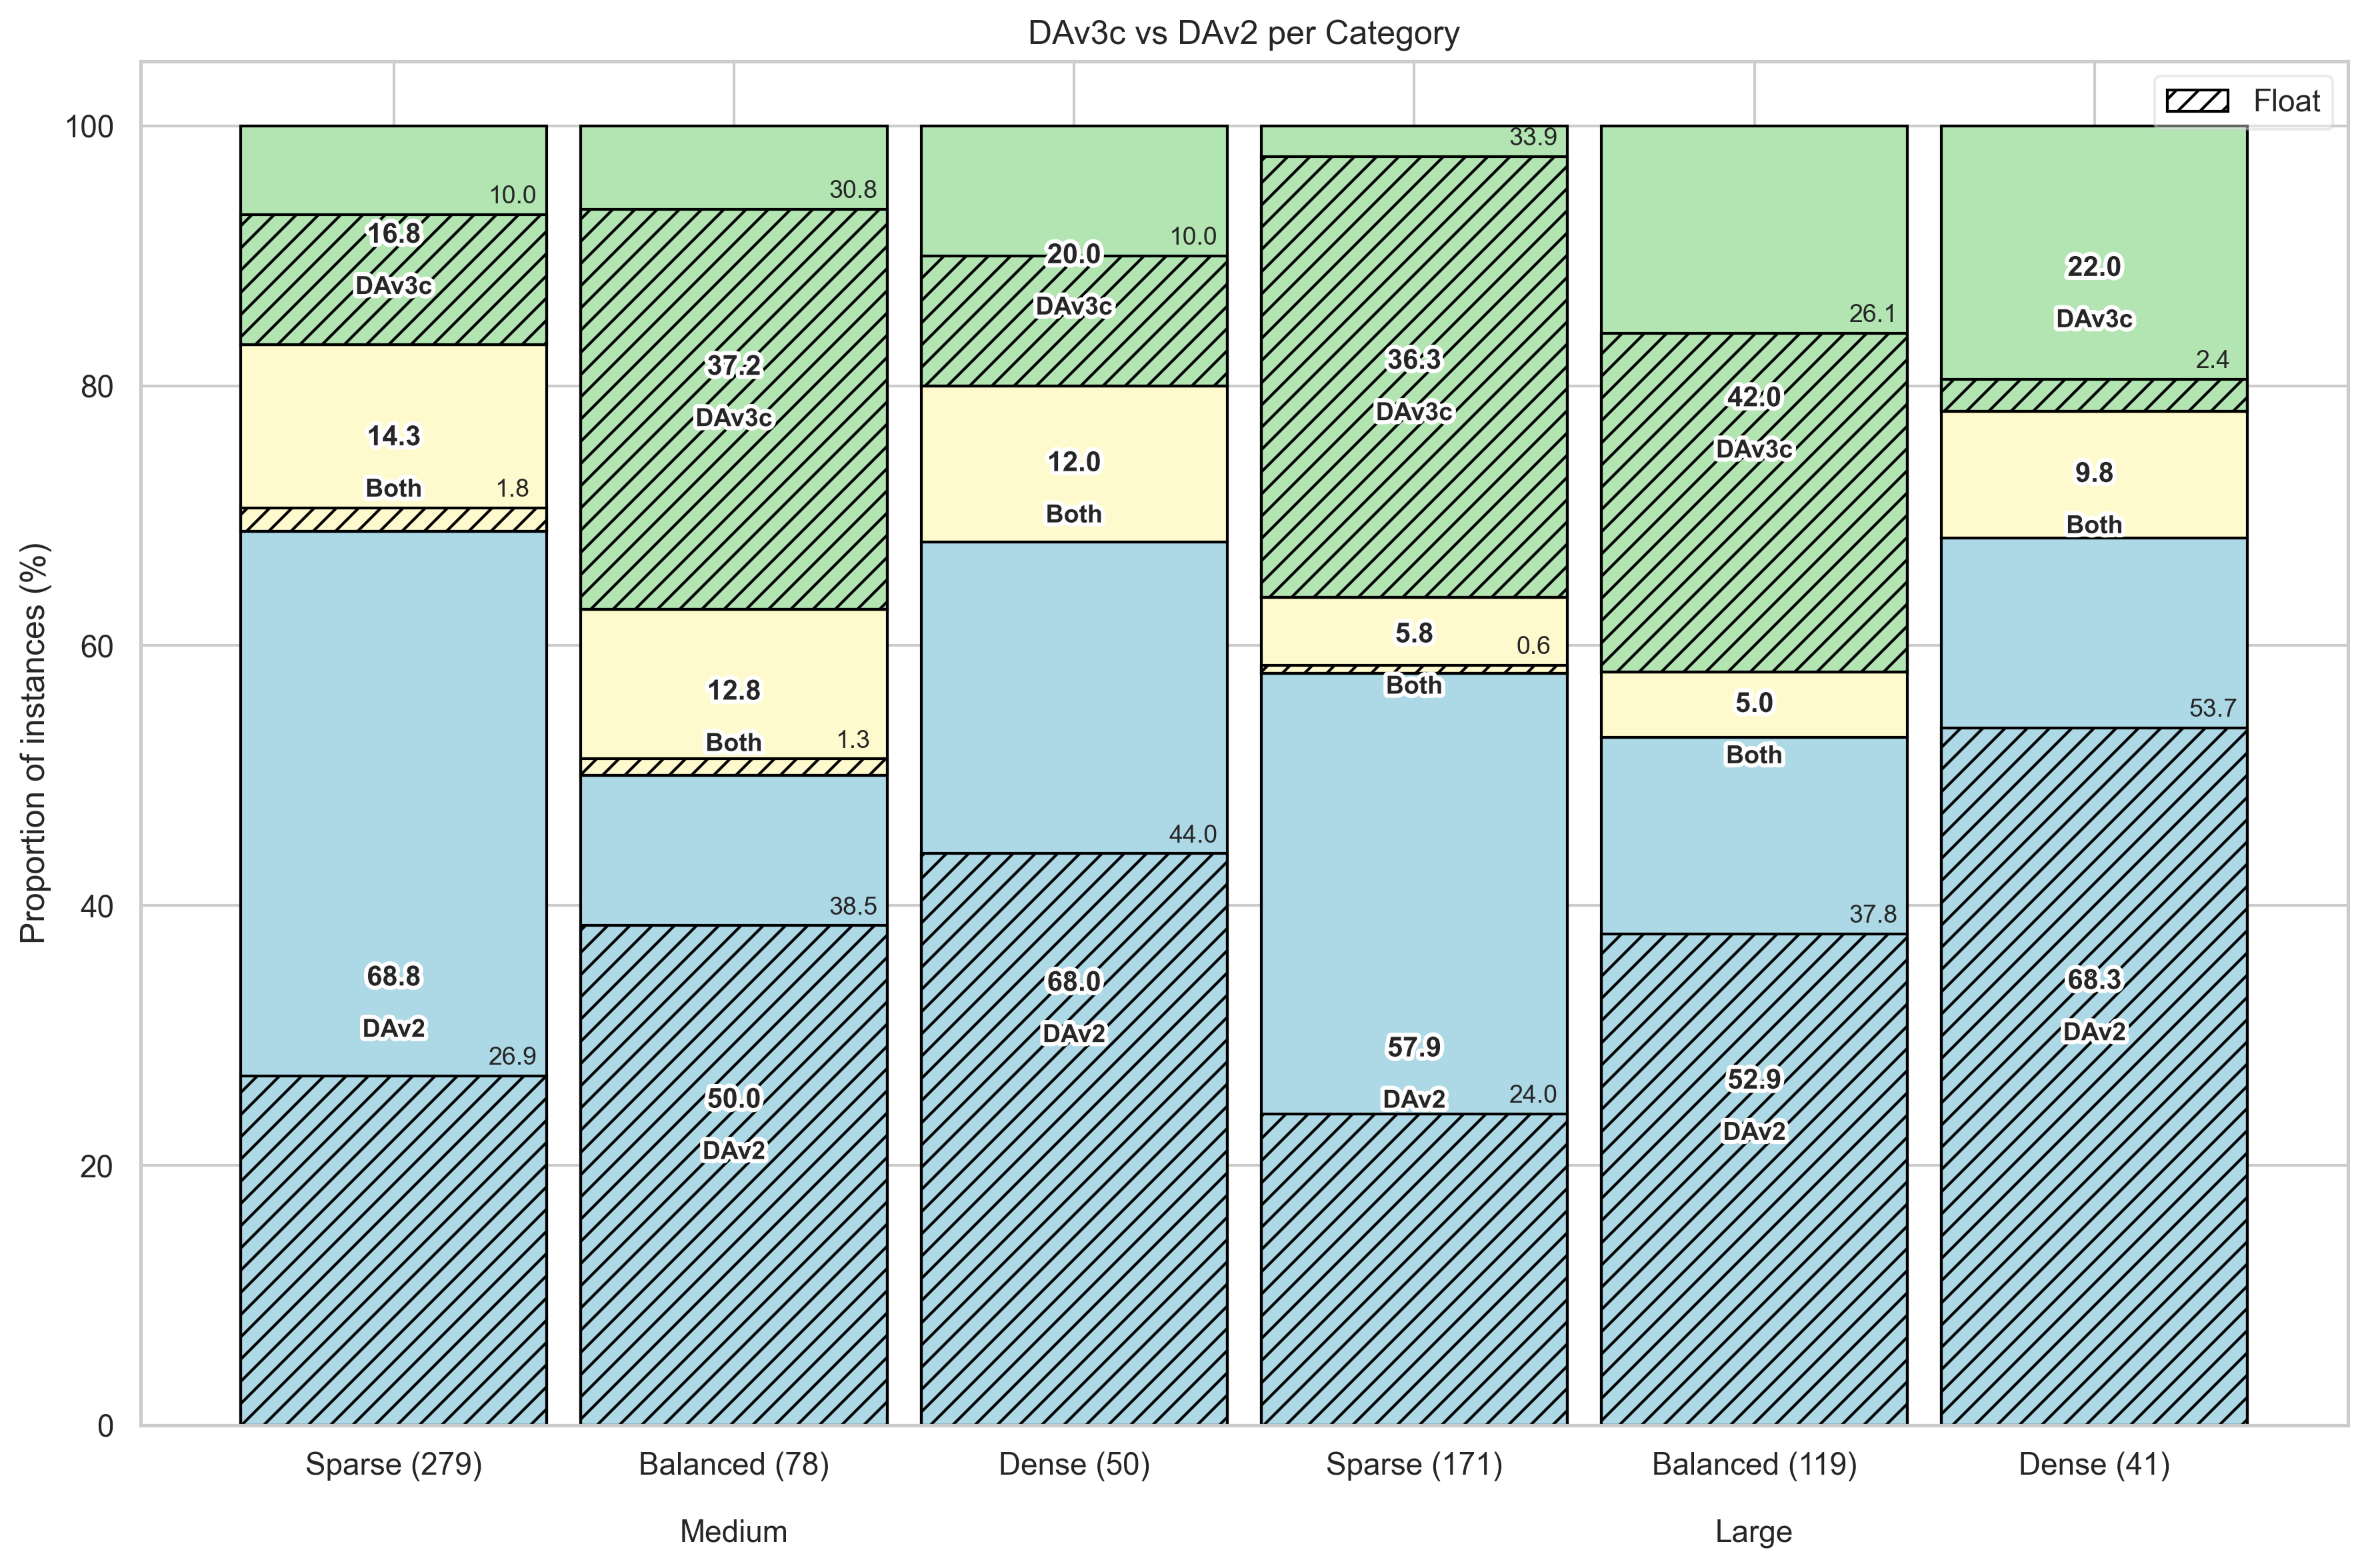

In [29]:
plotting.plot_win_tie_loss_with_float_hatch(
    summary=summary_dav2,
    pivot_table=pivot_table_dav2,
    title="DAv3c vs DAv2 per Category",
    win_label="DAv3c",
    loss_label="DAv2",
    use_category_loss_labels=False,
    save_name="dav3c_vs_dav2_category.pdf",
)

Validation check:
Tie count: 76
Ratio == 1.0: 76


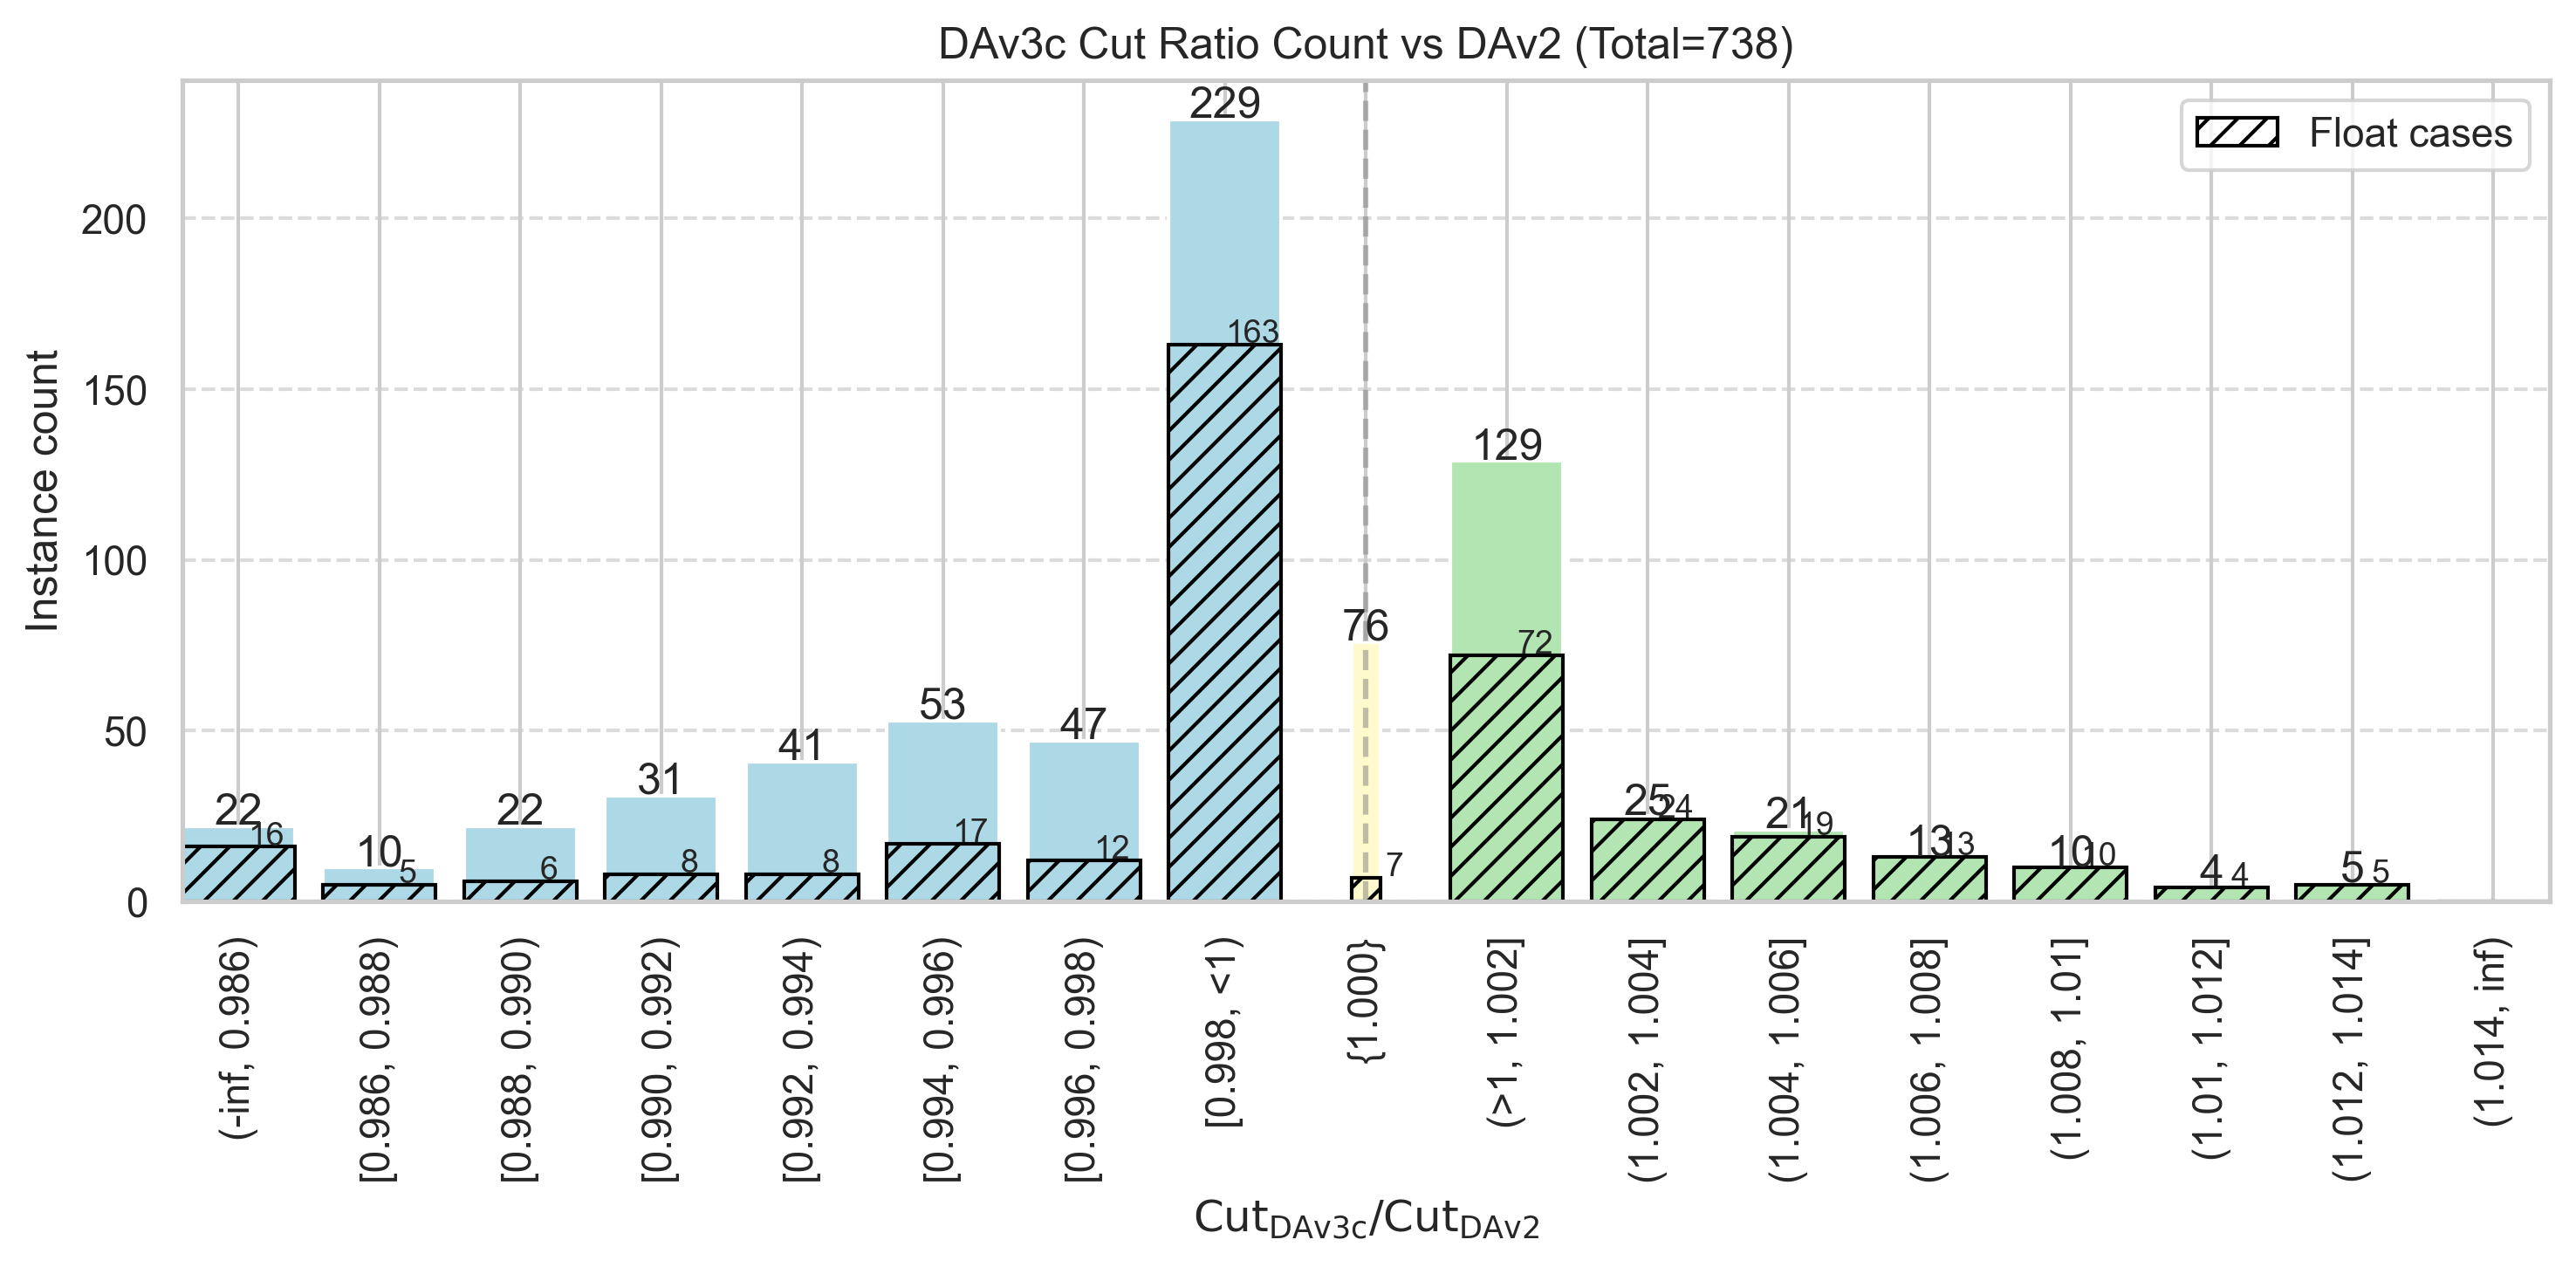

In [30]:
ratio_result_dav2 = utils.compute_cut_ratio_counts(
    df=df_dav2,
    solver_col="DAv3c",
    baseline_col="DAv2",
    int_col="int_only",
)

print('Validation check:')
print("Tie count:", ratio_result_dav2["tie_count"])
print("Ratio == 1.0:", ratio_result_dav2["ratio_one_count"])

fig, ax = plotting.plot_cut_ratio_counts(
    ratio_result_dav2,
    solver_label="DAv3c",
    baseline_label="DAv2",
    save_path=cfg.FIGURE_DIR / "DAv3c_DAv2_Cut_Ratio_Count.pdf",
)

In [31]:
utils.run_wilcoxon(df_dav2, "DAv3c", "DAv2", "DAv3c vs DAv2")


=== DAv3c vs DAv2 ===
Total paired samples: 738
Numerical ties: 76
Samples used: 662
Wilcoxon statistic: 79456.0
p-value: 7.7785e-10
Rank-biserial correlation: -0.2759
Median difference: -100
Result: Statistically significant (unadjusted)


{'n_total': 738,
 'n_nonzero': 662,
 'n_ties': 76,
 'stat': np.float64(79456.0),
 'p_raw': np.float64(7.778464349562325e-10),
 'r_rb': np.float64(-0.2758722824477223)}

In [32]:
res_dav2 = utils.wilcoxon_by_category(df_dav2, "DAv3c", "DAv2")
utils.print_wilcoxon_Pairwise_results(res_dav2 , "DAv3c vs DAv2 (Category-wise)")


=== DAv3c vs DAv2 (Category-wise) ===
large_balanced       | n=113 | ties=  6 | p_raw=8.4852e-02 | p_holm=1.6970e-01 | r_rb=-0.187 | Not significant
large_dense          | n= 37 | ties=  4 | p_raw=6.8601e-03 | p_holm=2.7441e-02 | r_rb=-0.502 | Significant
large_sparse         | n=161 | ties= 10 | p_raw=4.5209e-01 | p_holm=4.5209e-01 | r_rb=+0.068 | Not significant
medium_balanced      | n= 68 | ties= 10 | p_raw=4.5707e-02 | p_holm=1.3712e-01 | r_rb=-0.279 | Not significant
medium_dense         | n= 44 | ties=  6 | p_raw=6.4758e-05 | p_holm=3.2379e-04 | r_rb=-0.661 | Significant
medium_sparse        | n=239 | ties= 40 | p_raw=1.4428e-11 | p_holm=8.6565e-11 | r_rb=-0.504 | Significant


In [33]:
import numpy as np
import pandas as pd

def prepare_combined_wtl(df_baseline):

    df = df_baseline[
        df_baseline["size_cat"].isin(["medium", "large"])
    ].copy()

    df["category"] = (
        df["size_cat"].astype(str)
        + "_"
        + df["density_cat"].astype(str)
    )

    df["weight_type"] = np.where(
        df["int_only"] == True,
        "integer",
        "float"
    )

    results = []

    for solver in ["DAv2", "DAv3", "DAv3c"]:

        temp = df[
            [
                "name",
                "category",
                "weight_type",
                solver,
                "heuristic"
            ]
        ].dropna().copy()

        temp["result"] = temp.apply(
            lambda row: utils.compare_scores(
                row[solver],
                row["heuristic"]
            ),
            axis=1
        )

        temp["solver"] = solver
        results.append(
            temp[["category", "weight_type", "solver", "result"]]
        )

    df_combined = pd.concat(results, ignore_index=True)

    pivot_df = (
        df_combined
        .groupby(["category", "weight_type", "solver", "result"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=["loss", "tie", "win"], fill_value=0)
        .reset_index()
    )

    return pivot_df

In [34]:
pivot_combined = prepare_combined_wtl(df_baseline)

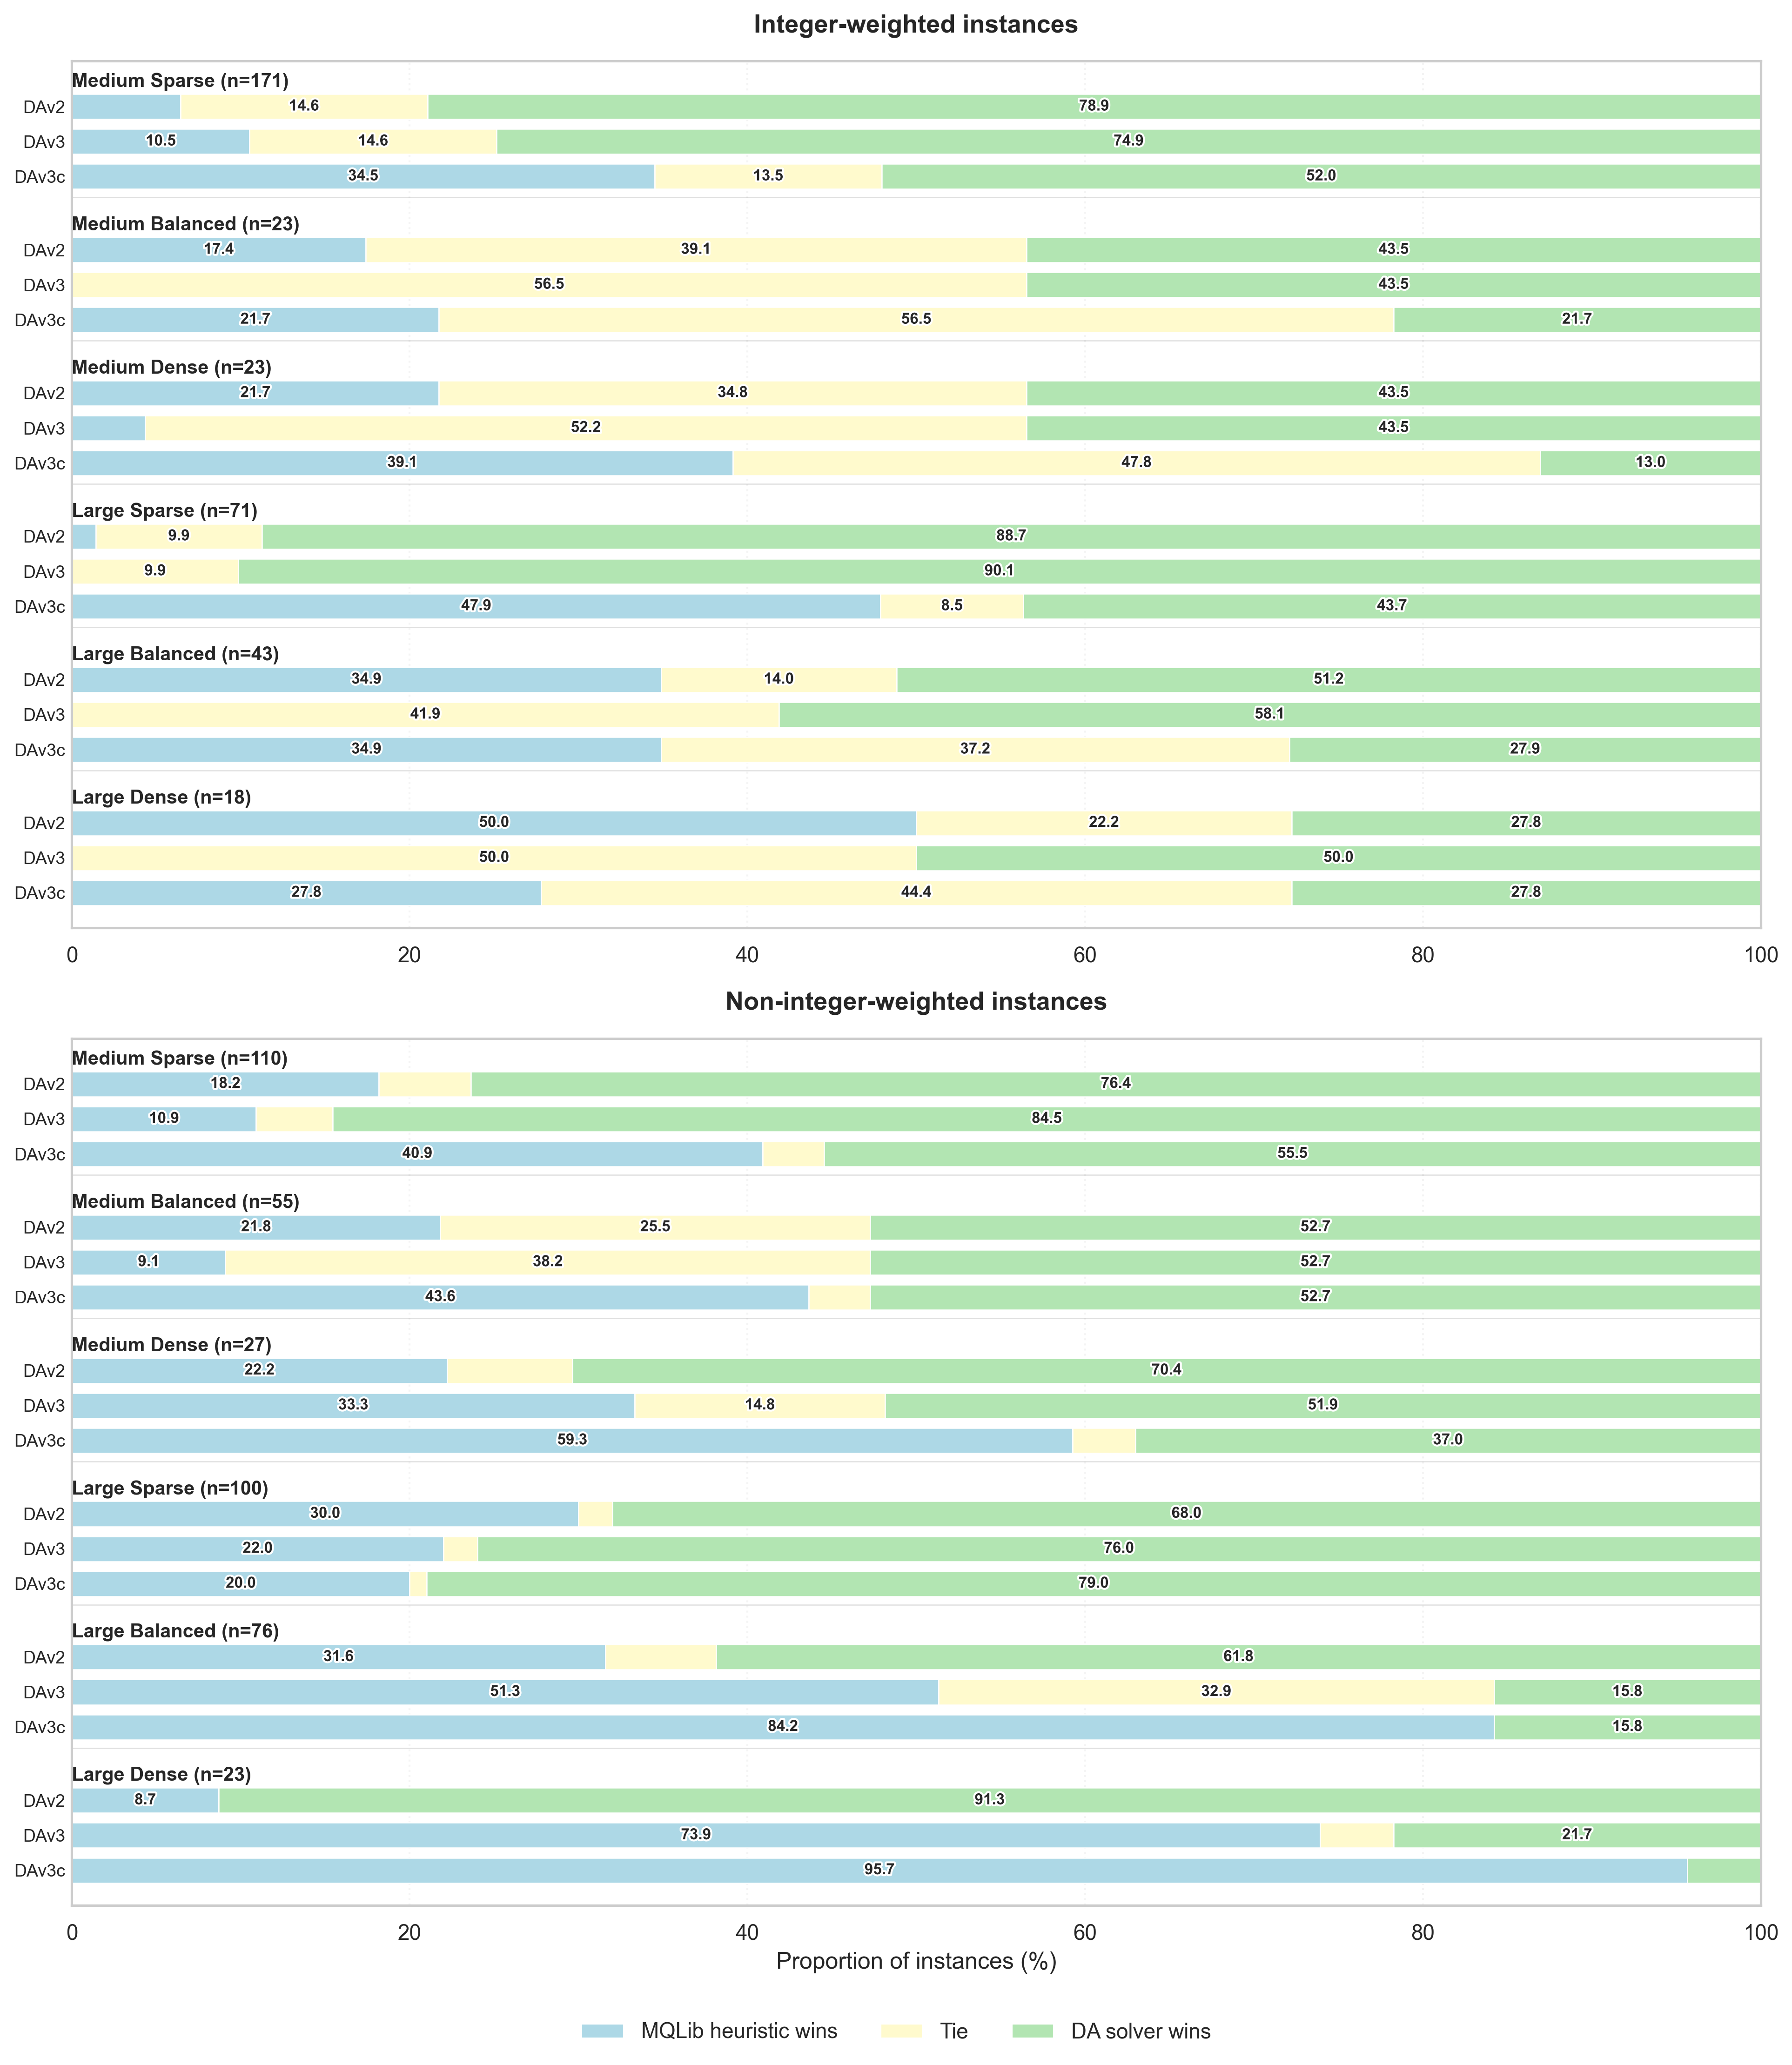

In [35]:
fig, axes = plotting.plot_combined_wtl_by_weight_type(
    pivot_df=pivot_combined,
    save_name="DA_vs_MQLib_integer_float_size_density.pdf",
    figsize=(13, 15)
)

(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv2 vs MQLib Heuristics'}, ylabel='Proportion of instances (%)'>)

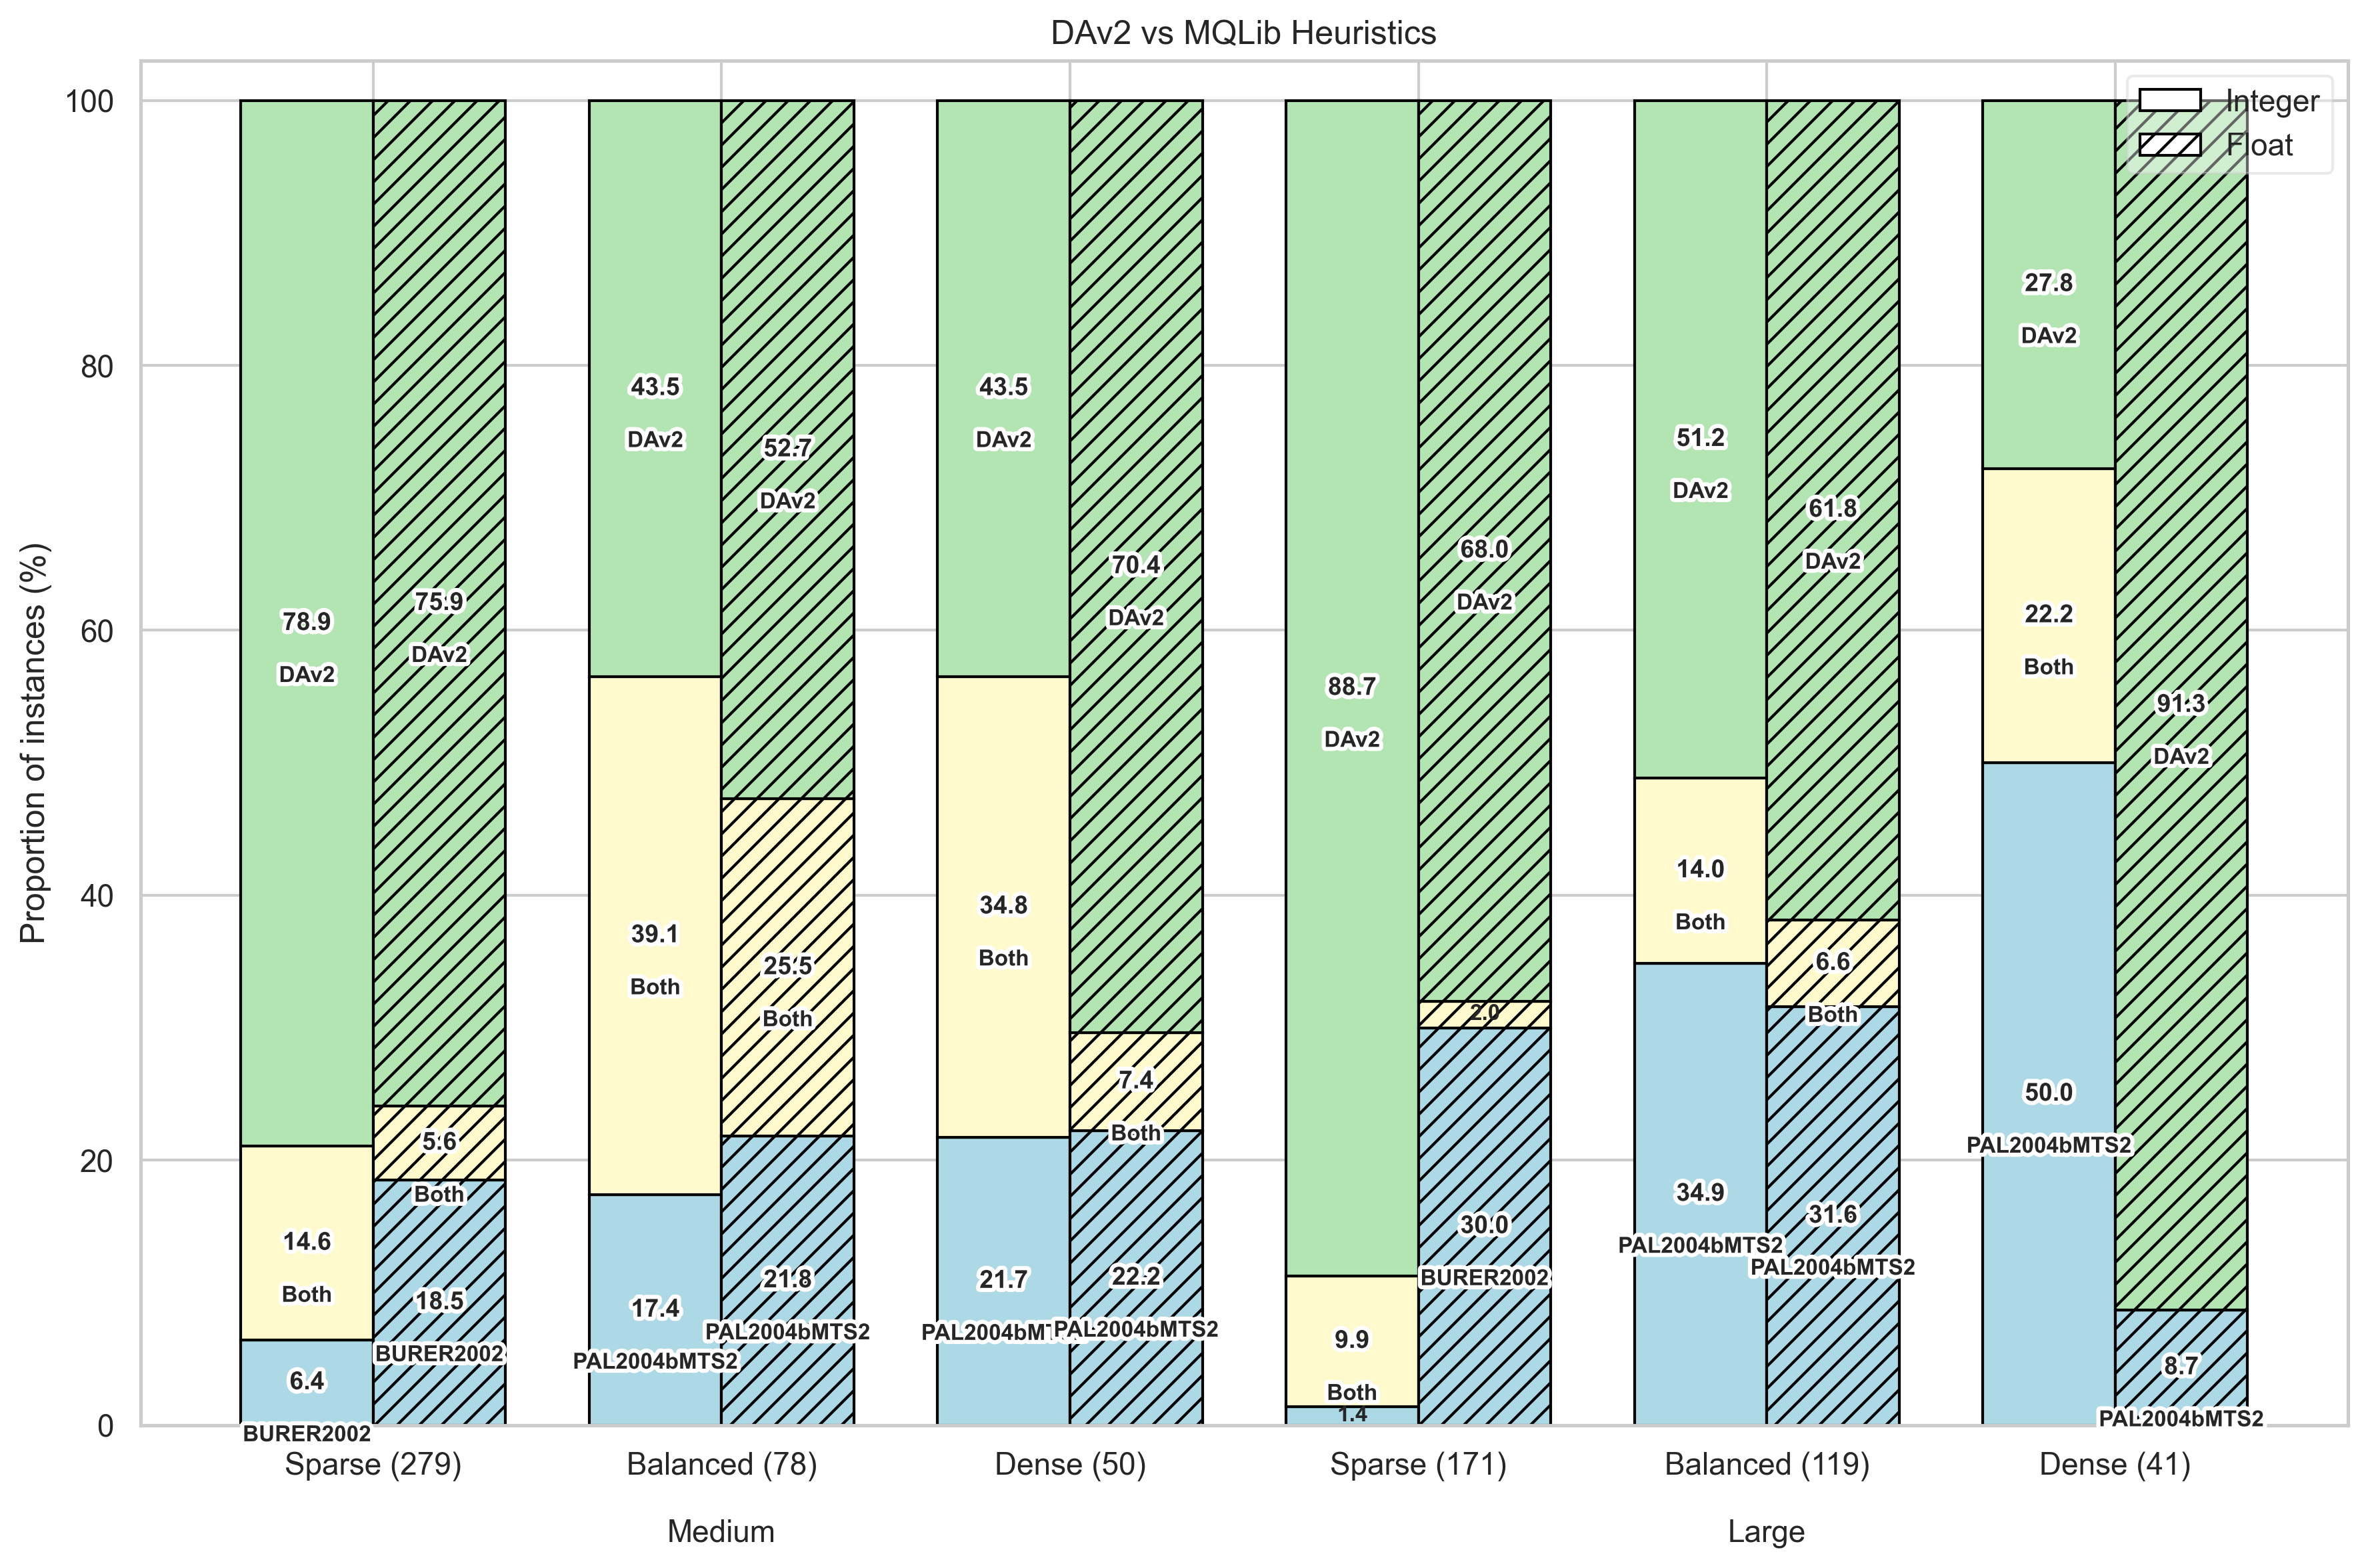

In [36]:
df_dav2_heu = df_dav2.copy()
df_dav2_heu ['result'] = df_dav2_heu .apply(lambda row: utils.compare_scores(row["DAv2"], row["heuristic"]), axis=1)
pivot_table_heu_v2, summary_heu_v2 = utils.conparison_summary(df_dav2_heu)

plotting.plot_win_tie_loss_by_weight_type(
    pivot_df=pivot_table_heu_v2,
    title="DAv2 vs MQLib Heuristics",
    save_name="dav2_vs heuristics_int_float_category.pdf",
    loss_label="Heuristic",
    win_label="DAv2",
    use_category_loss_labels=True,
)

(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv3 vs MQLib Heuristics'}, ylabel='Proportion of instances (%)'>)

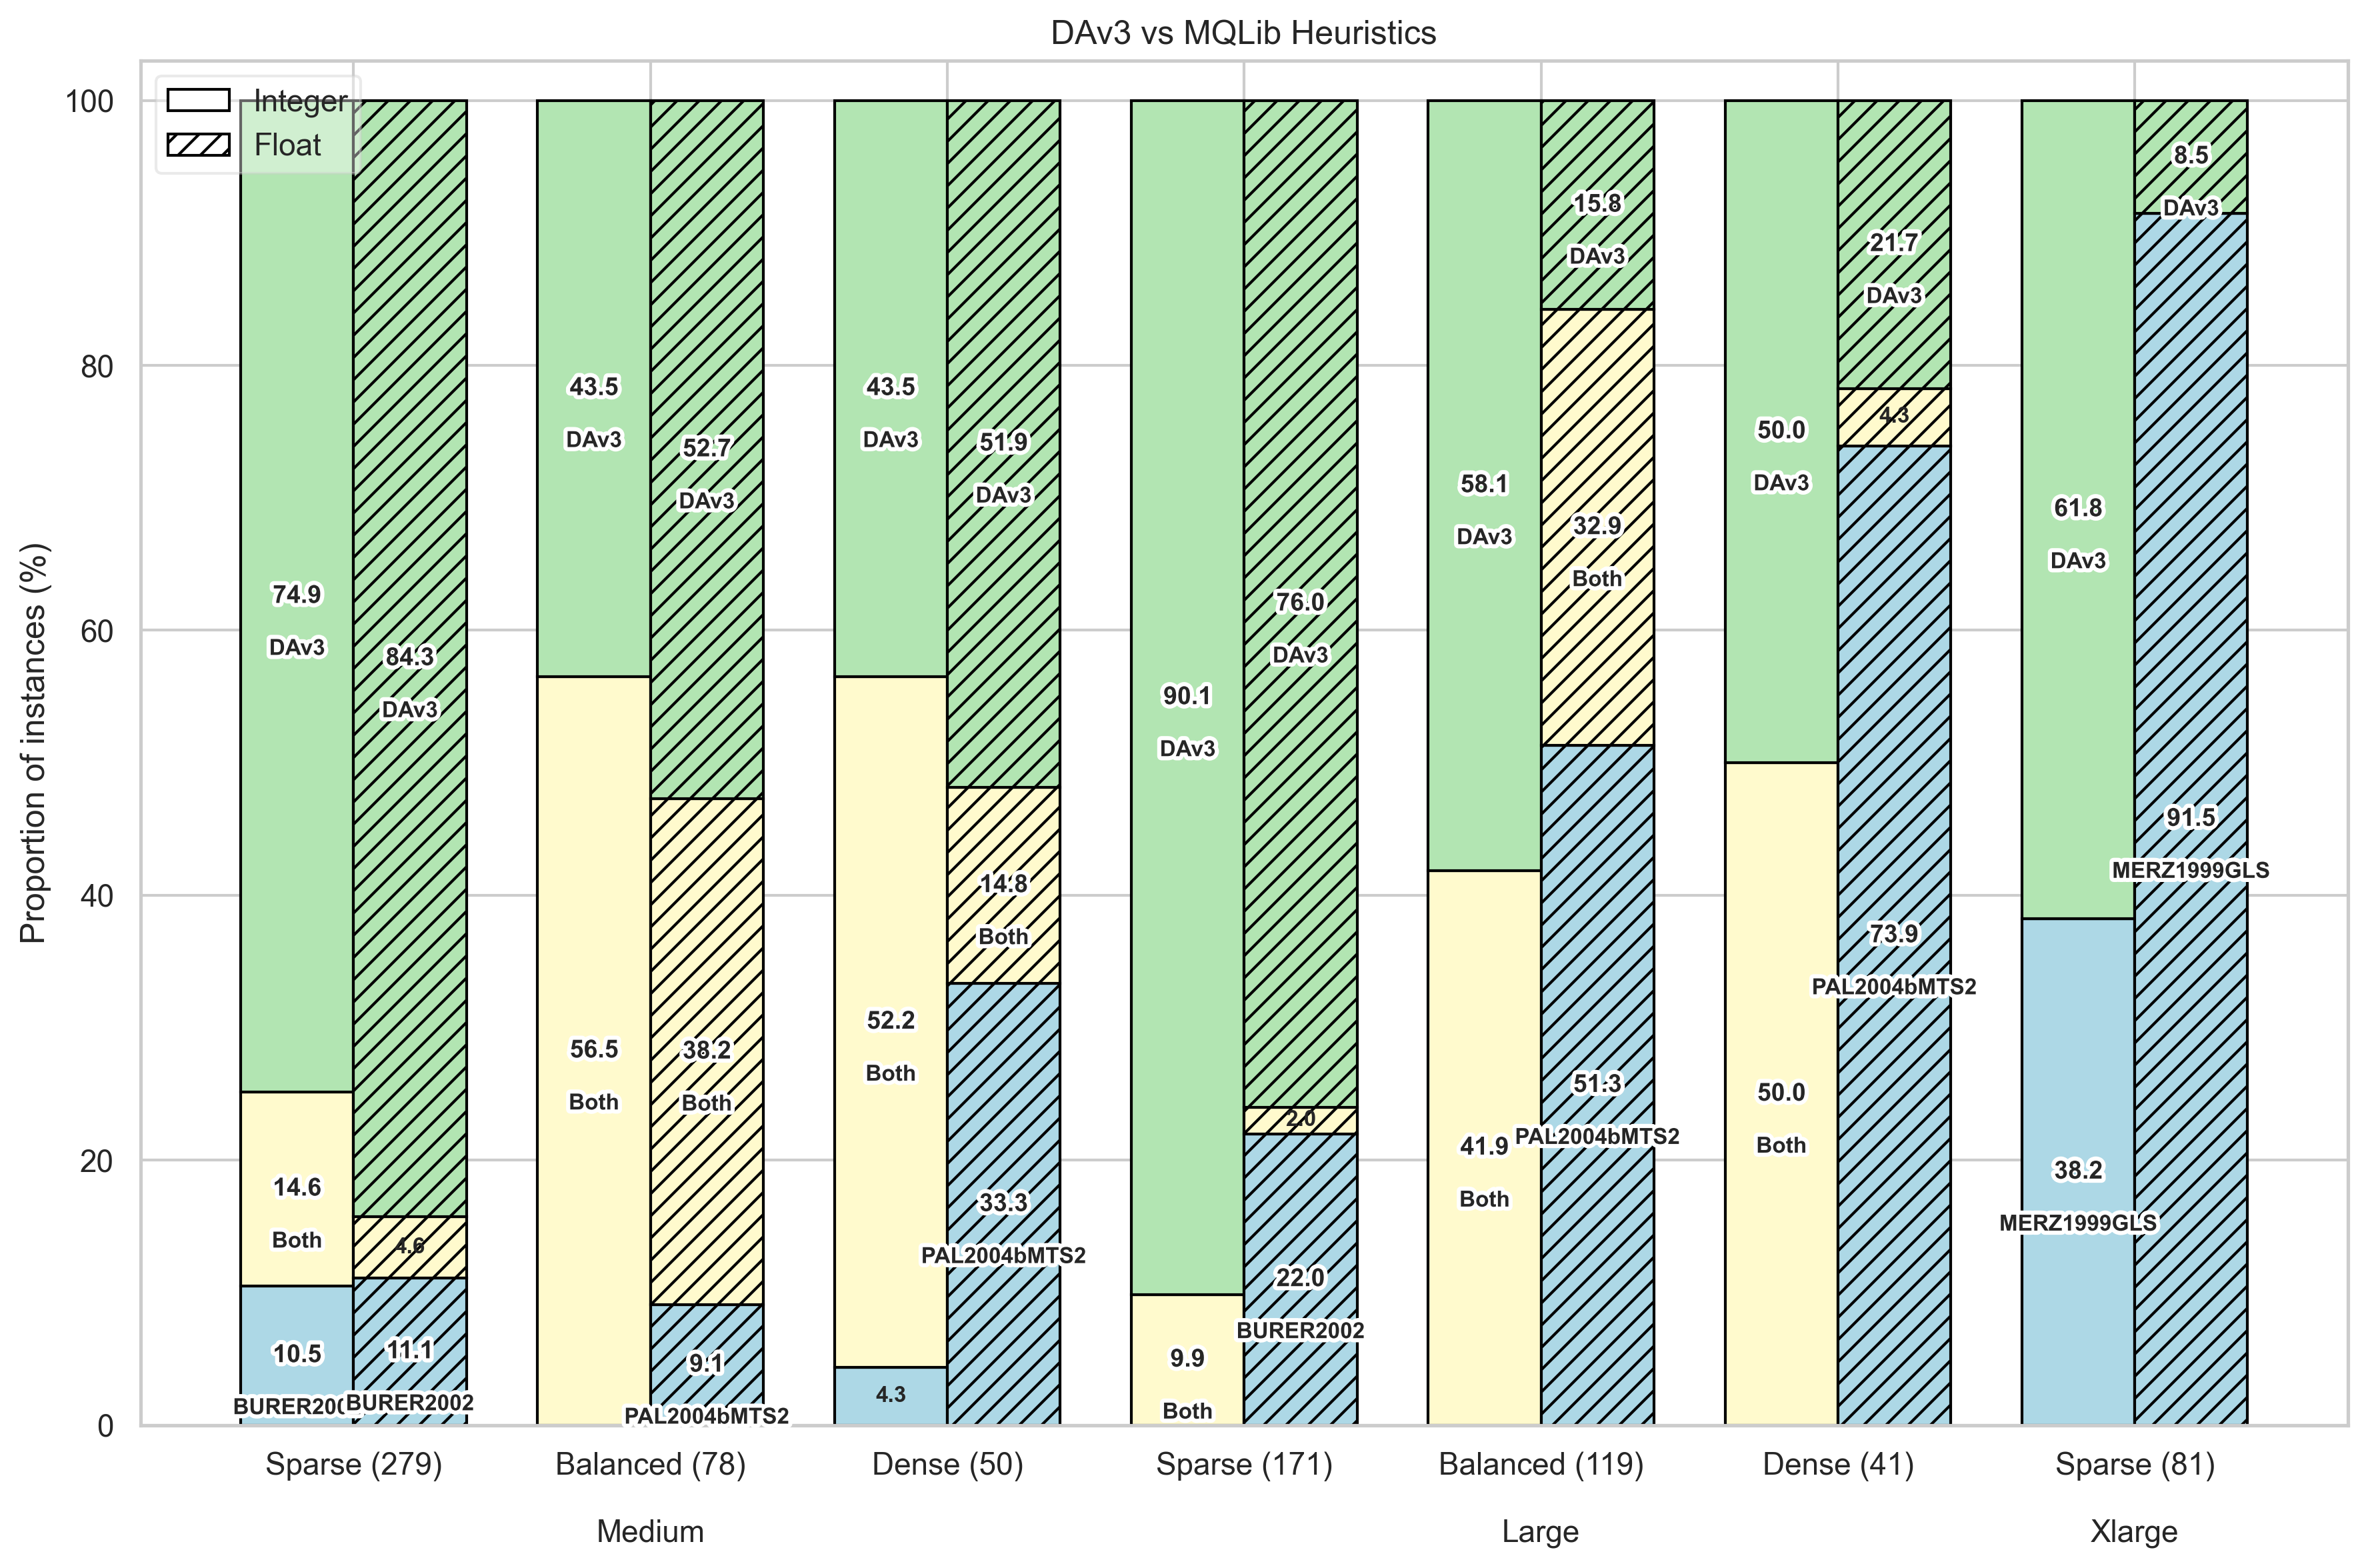

In [37]:
df_dav3_heu = df_dav3.copy()
df_dav3_heu ['result'] = df_dav3_heu .apply(lambda row: utils.compare_scores(row["DAv3"], row["heuristic"]), axis=1)
pivot_table_heu_v3, summary_heu_v3 = utils.conparison_summary(df_dav3_heu)


plotting.plot_win_tie_loss_by_weight_type(
    pivot_df=pivot_table_heu_v3,
    title="DAv3 vs MQLib Heuristics",
    save_name="dav3_vs_heuristics_int_float_category.pdf",
    loss_label="Heuristic",
    win_label="DAv3",
    use_category_loss_labels=True,
)

(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv3c vs MQLib Heuristics'}, ylabel='Proportion of instances (%)'>)

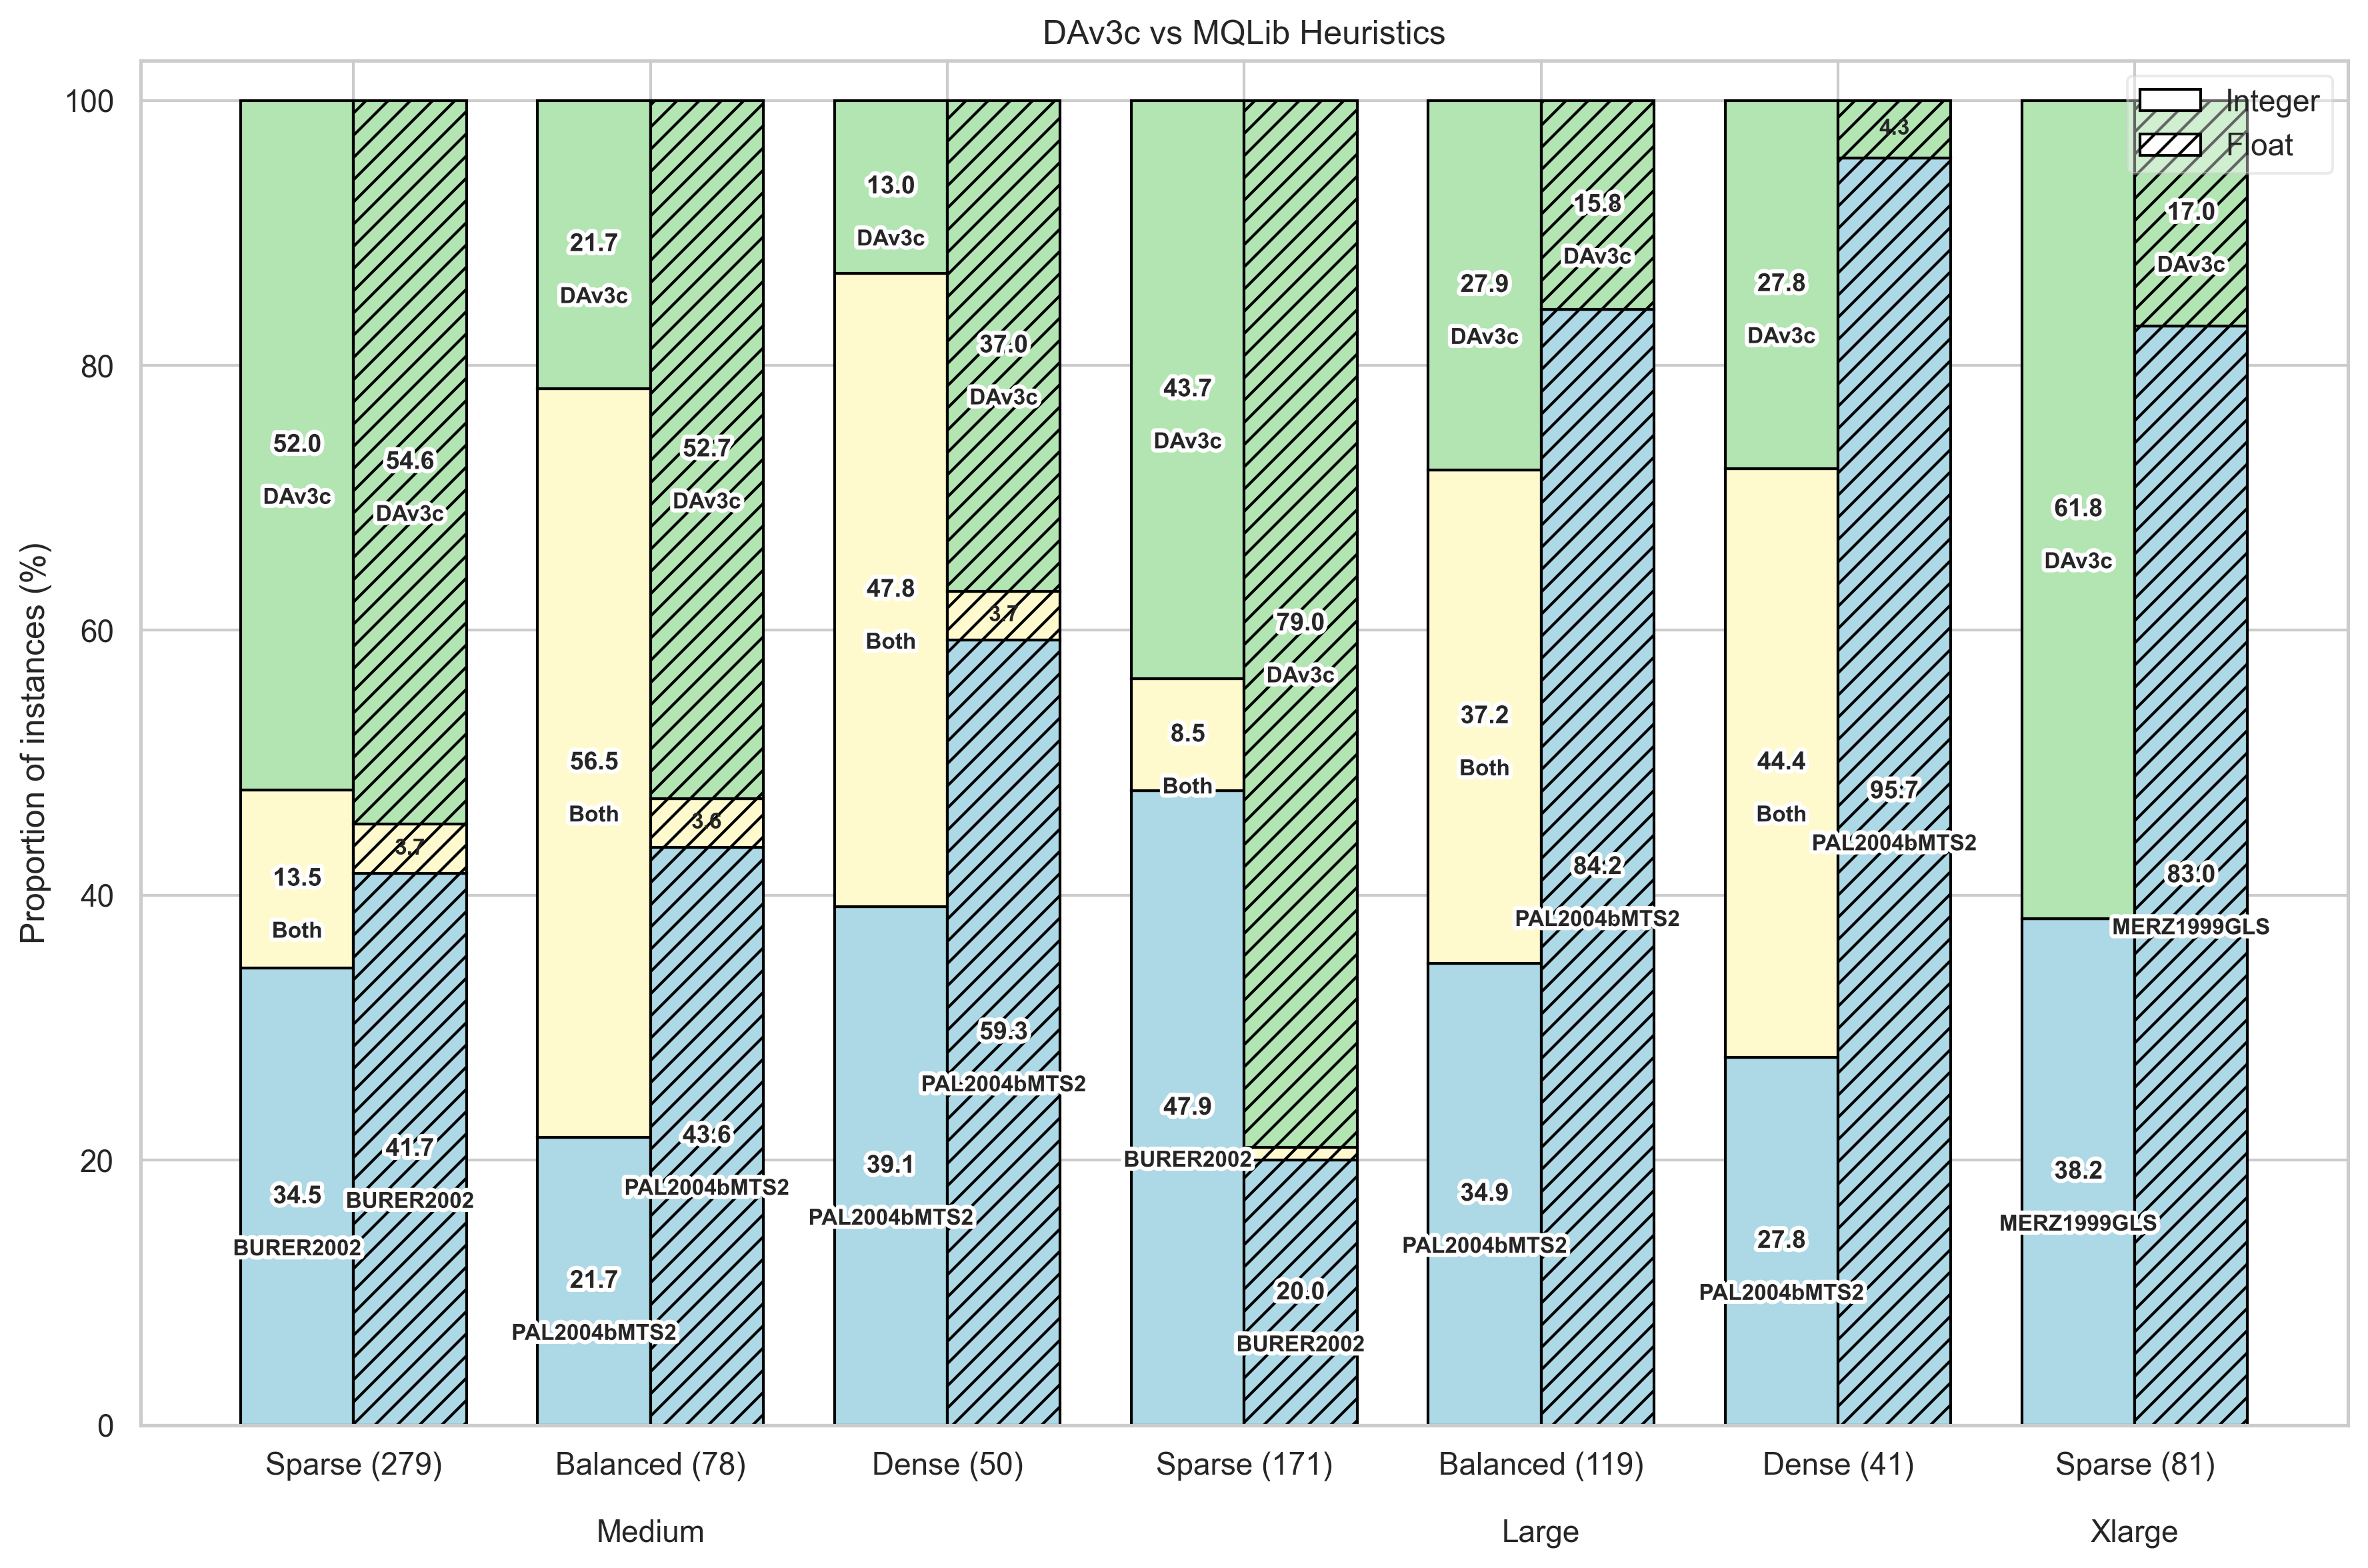

In [38]:
plotting.plot_win_tie_loss_by_weight_type(
    pivot_df=pivot_table_heu,
    title="DAv3c vs MQLib Heuristics",
    save_name="dav3c_vs_heuristics_int_float_category.pdf",
    loss_label="Heuristic",
    win_label="DAv3c",
    use_category_loss_labels=True,
)

result solver weight_type  loss  tie  win
0        DAv2       float    94   29  266
1        DAv2     integer    45   59  245
2        DAv3       float   104   58  227
3        DAv3     integer    19   84  246
4       DAv3c       float   191    8  190
5       DAv3c     integer   127   77  145


(<Figure size 3000x1800 with 1 Axes>,
 <Axes: title={'center': 'DA Solvers vs MQLib Heuristics by Weight Type'}, ylabel='Proportion of instances (%)'>)

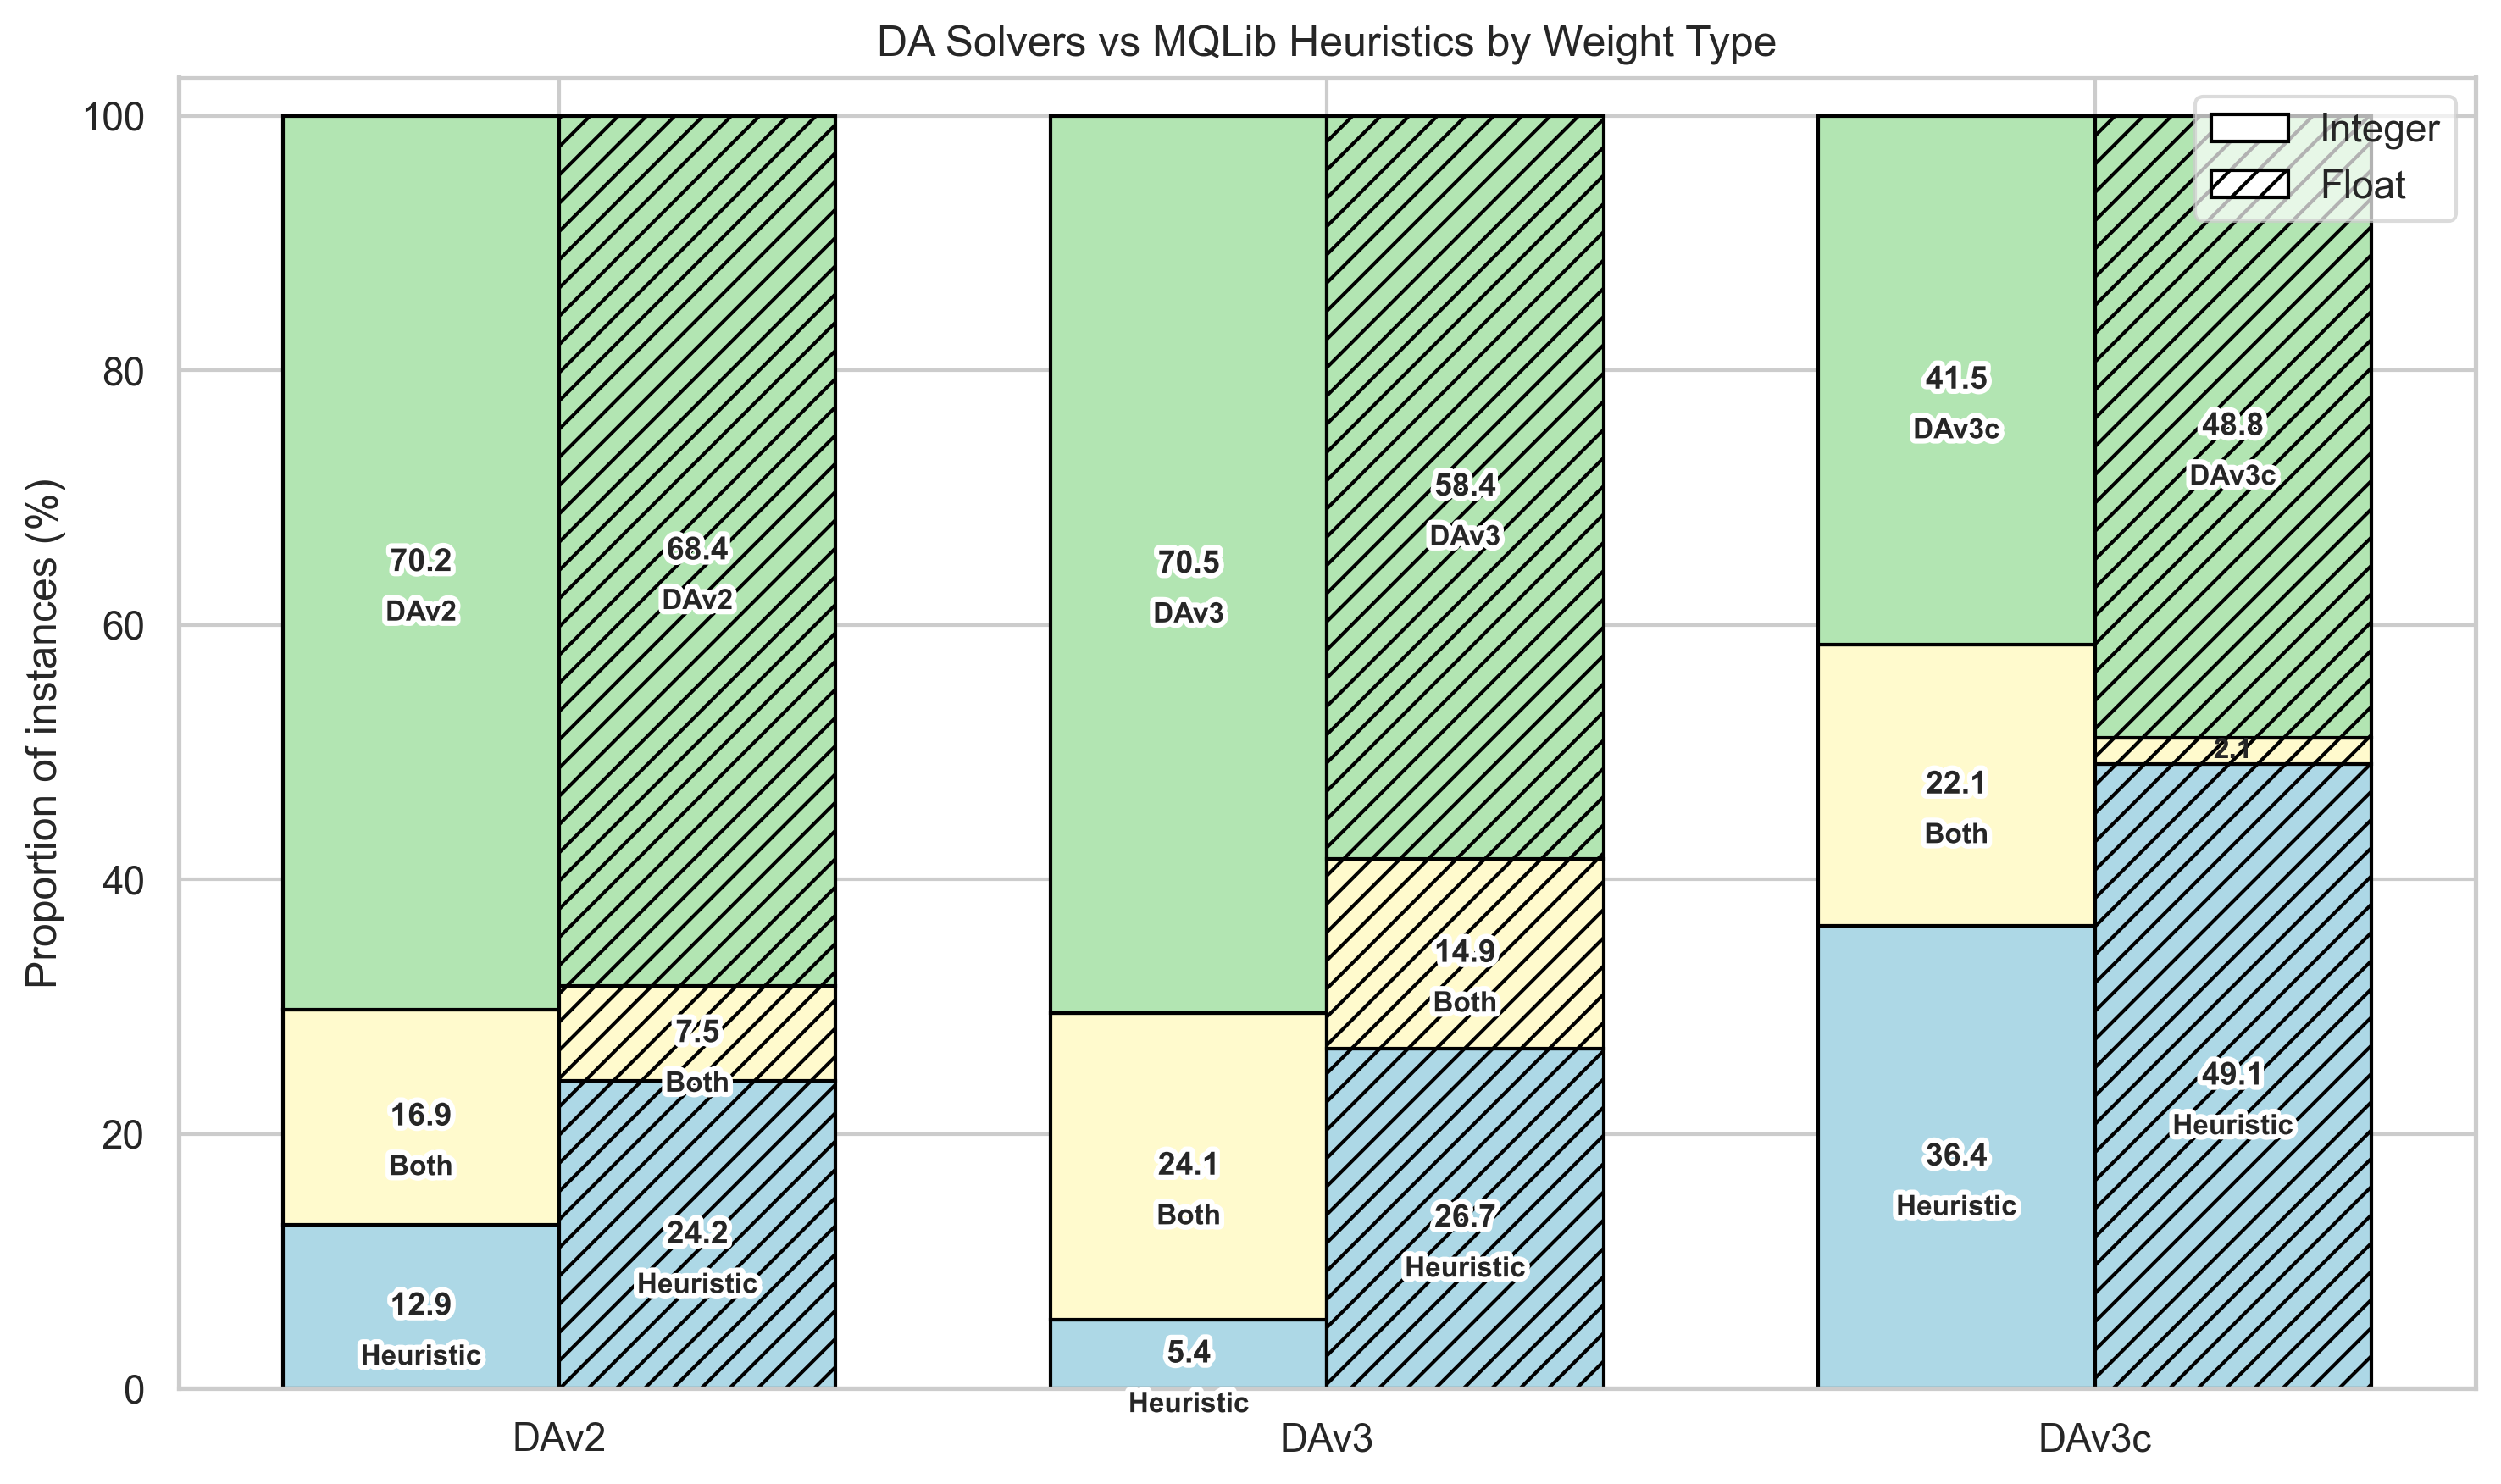

In [39]:
df_dav3_ = df_dav3_heu[~df_dav3_heu['size_cat'].isin(['xlarge'])]
df_dav3c_ = df_heu[~df_heu['size_cat'].isin(['xlarge'])]
summary = utils.tie_loss_win_counts(
    df_dav2_heu,
    df_dav3_,
    df_dav3c_
)
print(summary)
plotting.plot_combined_solver_weighttype_wtl(
    summary=summary,
    title="DA Solvers vs MQLib Heuristics by Weight Type",
    save_name="combined_solver_weighttype_wtl.pdf",
    loss_label="Heuristic",
    win_label="Solver",
)

In [40]:
df_dav3_['int_only'].count()

np.int64(738)

In [41]:
import pandas as pd
import numpy as np

# Use the same 738 common instances as the weight-type plot
df_dav2 = df_dav2_heu.copy()

df_dav3 = df_dav3_heu[
    ~df_dav3_heu["size_cat"].isin(["xlarge"])
].copy()

df_dav3c = df_heu[
    ~df_heu["size_cat"].isin(["xlarge"])
].copy()

# Create integer / non-integer categories
for df in [df_dav2, df_dav3, df_dav3c]:
    df["weight_type"] = np.where(
        df["int_only"].astype(bool),
        "integer",
        "float"
    )

# Run paired Wilcoxon tests for each solver
results = []

for solver_name, df in [
    ("DAv2", df_dav2),
    ("DAv3", df_dav3),
    ("DAv3c", df_dav3c),
]:
    res = utils.wilcoxon_by_category(
        df,
        col_a=solver_name,
        col_b="heuristic",
        category_col="weight_type",
        eps=1e-9
    )

    res.insert(0, "solver", solver_name)
    results.append(res)

df_significance = pd.concat(results, ignore_index=True)

display(
    df_significance[
        [
            "solver",
            "category",
            "n_total",
            "n_nonzero",
            "n_ties",
            "p_raw",
            "p_holm",
            "r_rb",
            "status"
        ]
    ]
)

,solver,category,n_total,n_nonzero,n_ties,p_raw,p_holm,r_rb,status
0,DAv2,float,389,360,29,1.204062e-08,1.204062e-08,0.346599,Significant
1,DAv2,integer,349,290,59,4.271613e-20,8.543225e-20,0.621993,Significant
2,DAv3,float,389,331,58,2.489975e-13,2.489975e-13,0.464201,Significant
3,DAv3,integer,349,265,84,8.218066e-25,1.643613e-24,0.728869,Significant
4,DAv3c,float,389,381,8,6.829402e-02,1.365880e-01,0.107776,Not significant
5,DAv3c,integer,349,272,77,9.478094e-01,9.478094e-01,0.004579,Not significant


In [42]:
ids_dav2 = set(df_dav2["name"])
ids_dav3 = set(df_dav3["name"])
ids_dav3c = set(df_dav3c["name"])

assert ids_dav2 == ids_dav3 == ids_dav3c
assert len(ids_dav2) == 738

print("All three solvers use the same 738 instances.")

All three solvers use the same 738 instances.


In [43]:
from statsmodels.stats.multitest import multipletests

reject, p_adjusted, _, _ = multipletests(
    df_significance["p_raw"].to_numpy(),
    alpha=0.05,
    method="holm"
)

df_significance["p_holm_all6"] = p_adjusted
df_significance["significant_all6"] = reject

display(df_significance[
    ["solver", "category", "p_raw", "p_holm_all6", "r_rb", "significant_all6"]
])

,solver,category,p_raw,p_holm_all6,r_rb,significant_all6
0,DAv2,float,1.204062e-08,3.612185e-08,0.346599,True
1,DAv2,integer,4.271613e-20,2.135806e-19,0.621993,True
2,DAv3,float,2.489975e-13,9.959901e-13,0.464201,True
3,DAv3,integer,8.218066e-25,4.930839e-24,0.728869,True
4,DAv3c,float,6.829402e-02,1.365880e-01,0.107776,False
5,DAv3c,integer,9.478094e-01,9.478094e-01,0.004579,False


In [44]:
for name, df in [
    ("DAv2", df_dav2),
    ("DAv3", df_dav3),
    ("DAv3c", df_dav3c),
]:
    print(f"\n{name}")
    print(df["weight_type"].value_counts())


DAv2
weight_type
float      389
integer    349
Name: count, dtype: int64

DAv3
weight_type
float      389
integer    349
Name: count, dtype: int64

DAv3c
weight_type
float      389
integer    349
Name: count, dtype: int64


In [45]:
summary_xlarge = utils.tie_loss_win_counts(
    df_dav3 = df_dav3_heu[df_dav3_heu['size_cat'].isin(['xlarge'])],
    df_dav3c= df_heu[df_heu['size_cat'].isin(['xlarge'])]
)
print(summary_xlarge)

result solver weight_type  loss  tie  win
0        DAv3       float    43    0    4
1        DAv3     integer    13    0   21
2       DAv3c       float    39    0    8
3       DAv3c     integer    13    0   21


In [46]:
comparisons = [
    {
        "df": df_dav2_heu,
        "solver_col": "DAv2",
        "baseline_col": "heuristic",
        "label": "DAv2 vs Heuristic",
    },
    {
        "df": df_dav3_heu,
        "solver_col": "DAv3",
        "baseline_col": "heuristic",
        "label": "DAv3 vs Heuristic",
    },
    {
        "df": df_heu,
        "solver_col": "DAv3c",
        "baseline_col": "heuristic",
        "label": "DAv3c vs Heuristic",
    },
]

In [47]:
df_dav3_heu['size_cat'].unique()

<ArrowStringArray>
['large', 'xlarge', 'medium']
Length: 3, dtype: str

In [48]:
for comp in comparisons:
    comp["df"]["weight_type"] = np.where(
        comp["df"]["int_only"],
        "integer",
        "float"
    )

In [50]:
df_small = utils.filter_small_instances(df_baseline,'heuristic')
df_small["category"] = (df_small["size_cat"] + "_" + df_small["density_cat"])
print(f'Total Number of Instances: {len(df_small)}')
print('............')
print(f'Size Category Distribution: {df_small['size_cat'].value_counts()}')
print('............')
print(f'Density Category Distribution: {df_small['density_cat'].value_counts()}')
print('............')
print(f'Density Category Distribution: {df_small['category'].value_counts()}')

Total Number of Instances: 1306
............
Size Category Distribution: size_cat
xsmall    1074
small      232
Name: count, dtype: int64
............
Density Category Distribution: density_cat
sparse      704
balanced    408
dense       194
Name: count, dtype: int64
............
Density Category Distribution: category
xsmall_sparse      525
xsmall_balanced    367
xsmall_dense       182
small_sparse       179
small_balanced      41
small_dense         12
Name: count, dtype: int64


In [51]:
df_small['result'] = df_small.apply(lambda row: utils.compare_scores(row["DAv3c"], row["heuristic"]), axis=1)

In [52]:
pivot_table_small, summary_small = utils.conparison_summary(df_small)
print(pivot_table_small)

result         category int_only   loss    tie    win weight_type  total
0         xsmall_sparse    False   21.0   25.0   71.0       float  117.0
1         xsmall_sparse     True   84.0   80.0  244.0     integer  408.0
12        xsmall_sparse    total  105.0  105.0  315.0       total  525.0
2       xsmall_balanced    False   38.0   82.0   72.0       float  192.0
3       xsmall_balanced     True    2.0  139.0   34.0     integer  175.0
13      xsmall_balanced    total   40.0  221.0  106.0       total  367.0
4          xsmall_dense    False   26.0   15.0   24.0       float   65.0
5          xsmall_dense     True   12.0   92.0   13.0     integer  117.0
14         xsmall_dense    total   38.0  107.0   37.0       total  182.0
6          small_sparse    False   15.0    2.0   20.0       float   37.0
7          small_sparse     True   45.0   33.0   64.0     integer  142.0
15         small_sparse    total   60.0   35.0   84.0       total  179.0
8        small_balanced    False    5.0    7.0   21

(<Figure size 3600x2400 with 1 Axes>,
 <Axes: title={'center': 'DAv3c vs MQLib Heuristics per Category'}, ylabel='Proportion of instances (%)'>)

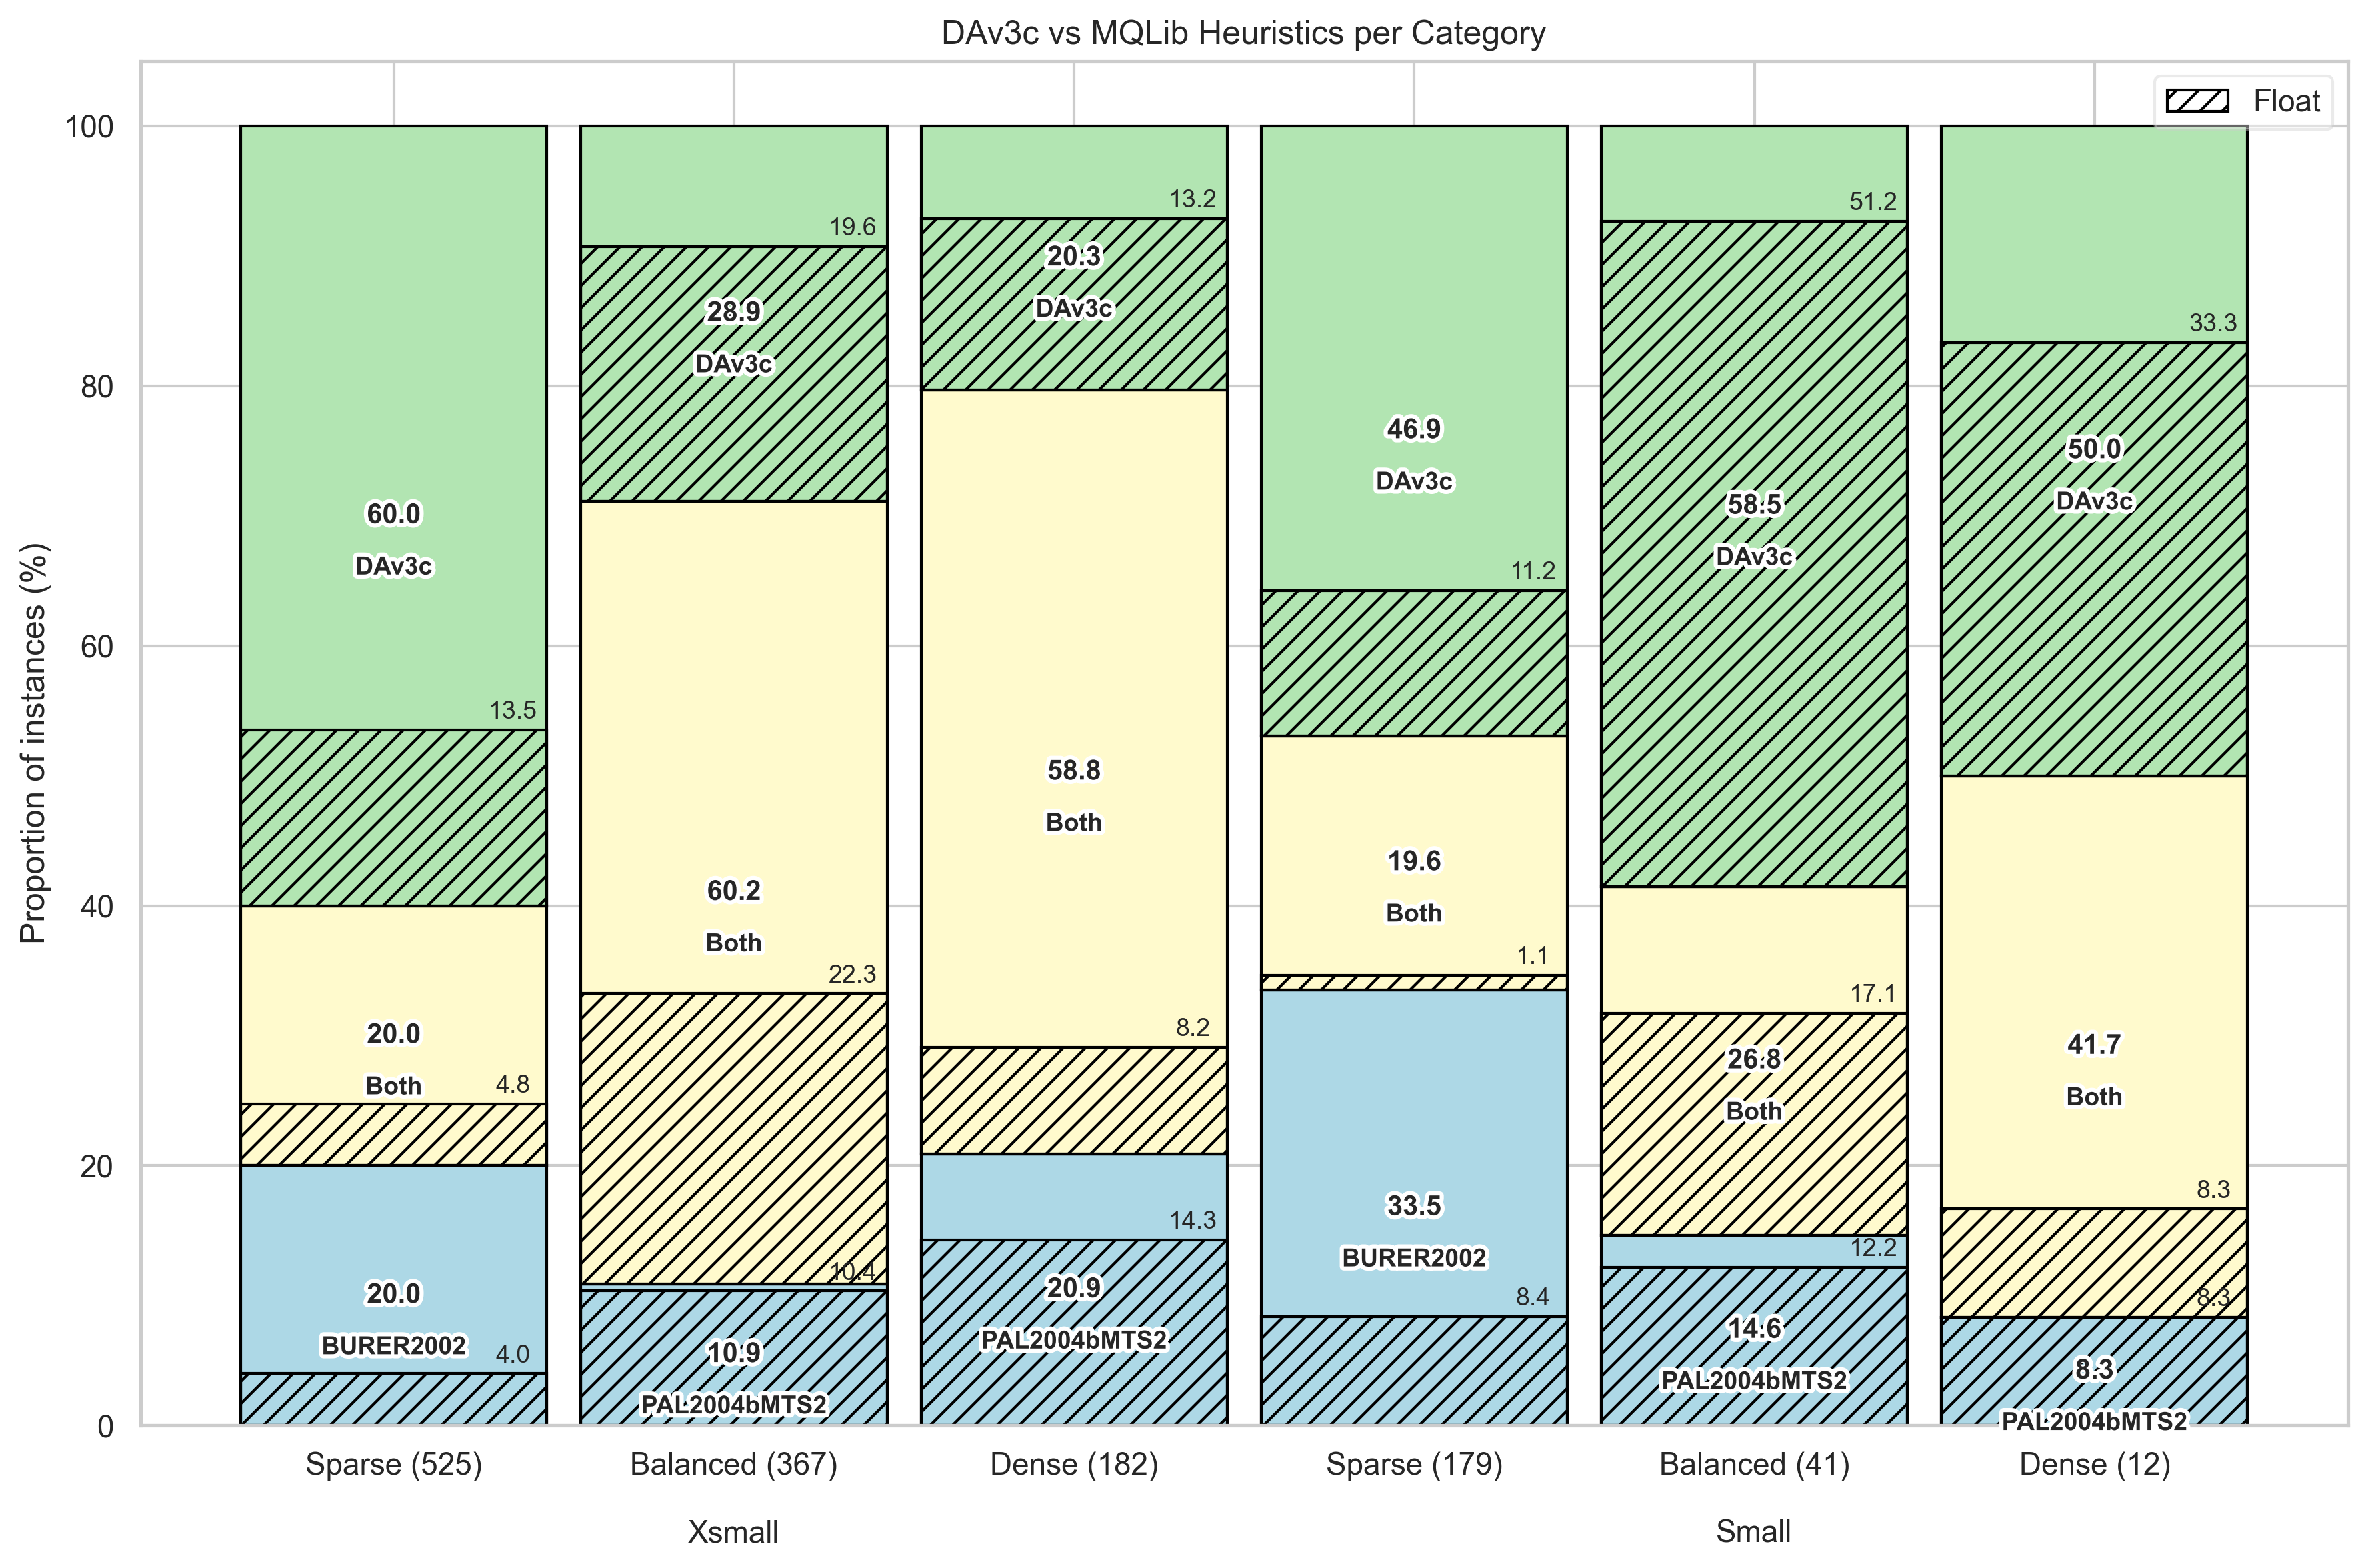

In [53]:
plotting.plot_win_tie_loss_with_float_hatch(
    summary=summary_small,
    pivot_table=pivot_table_small,
    title="DAv3c vs MQLib Heuristics per Category",
    win_label="DAv3c",
    loss_label="Heuristic",
    use_category_loss_labels=True,
    save_name="dav3c_vs_heuristics_small_category.pdf",
)